# Can tagged DRN units be identified without opto-tagging?

Unsupervised test: cluster DRN units into 2 groups using spontaneous-activity and waveform features alone, then ask how well the clusters line up with the opto-tagging labels. Labels are used **only for evaluation**, never for fitting.

**Populations**
* **Matched** (main): the tagged and matched non-tagged units of the unit_summary_DRN PDFs.
  * Tagged units pass `TAGGED_CRITERION`.
  * Non-tagged units are the nearest-neighbor controls on the same insertion, from `nontagged_matched_selection.csv`.
  * Each unit uses the drift cut of its summary page.
* **Unidentified** (larger): tagged units plus every unit in the same sessions that passes QC and never responded to light (see `tagged_classifier_features.unidentified_units`).
  * These units have **no drift cuts**, so everyone in this population, tagged units included, is computed over the whole recording.
  * The *drift-cut sensitivity* section measures what that costs, using the units that do have cuts.

**Feature groups:**
* firing rate
* local variation (LV)
* waveform shape (center channel)
* ACG shape: hand-picked metrics and PCA components
* optionally, the sorter's multi-channel `template_metrics`

**Methods**
* **k-means:** k = 2 on transformed features.
* **Expectation-maximization:** follows the precedent: *"Expectation-maximization clustering was performed using hierarchical clustering for parameterized Gaussian mixture models, setting the number of clusters to 2 ... with model selection by Bayesian Information Criterion"* (R's `mclust`). Here:
  * Each GMM is initialized from a 2-cluster Ward hierarchical partition.
  * One model is fit per covariance parameterization, and the winner is chosen by BIC.
  * sklearn offers 4 of mclust's 14 parameterizations: `spherical` ≈ VII, `diag` ≈ VVI, `tied` ≈ EEE, `full` ≈ VVV.
  * sklearn's BIC is "lower is better"; mclust's is "higher is better".
* **Supervised reference:** session-held-out logistic regression, which gives a ceiling on how much label information the features carry.

Features are computed by [tagged_classifier_features.py](tagged_classifier_features.py) and cached. The first build takes a few minutes; set `REBUILD_FEATURES = True` after the unit sets or drift cuts change.

In [1]:
import sys, os, warnings
sys.path.insert(0, '/root/capsule/code/beh_ephys_analysis')

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.stats import mannwhitneyu, spearmanr
from sklearn.preprocessing import PowerTransformer, StandardScaler
from sklearn.cluster import KMeans, AgglomerativeClustering
from sklearn.mixture import GaussianMixture
from sklearn.decomposition import PCA
from sklearn.metrics import adjusted_rand_score, roc_auc_score
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import StratifiedGroupKFold, cross_val_predict
from sklearn.pipeline import make_pipeline

# unit_summary_DRN (imported by the feature module) sets the Agg backend, so %matplotlib inline comes after it
from tagged_classifier_features import build_features, LAG_SHORT_MS, LAG_LONG_MS

%matplotlib inline
warnings.filterwarnings('ignore', category=FutureWarning)

# ----------------------------- knobs -----------------------------
REBUILD_FEATURES = False
JOBS = 8
MIN_SPIKES = 200          # spontaneous spikes needed for ACG / LV
USE_TEMPLATE_METRICS = True
# template_metrics columns used. Left out: velocity_above/below (missing for 56-70% of units),
# num_positive/negative_peaks (almost all 1), and spread (only ~10 values in 15 um steps, AUC 0.45:
# a full-covariance GMM latches onto the discrete levels, which drops the EM ARI on
# all + template metrics from 0.48 to 0.02)
TM_COLS = ['tm_peak_to_valley', 'tm_half_width', 'tm_peak_trough_ratio', 'tm_repolarization_slope',
           'tm_recovery_slope', 'tm_exp_decay']
N_ACG_PCS = 3
ACG_PCA_CLIP = 3.0        # ACG bins are clipped to [0, this] before PCA so a few bursty units don't dominate
# unidentified population: None = every QC unit in the sessions; a number keeps units within
# this many mm (DV) of the session's tagged range
UNID_MAX_DV_OUTSIDE_MM = None
TRANSFORM = 'yeo-johnson'  # 'yeo-johnson' or 'zscore'
COV_TYPES = ['spherical', 'diag', 'tied', 'full']
N_SHUFFLE = 1000           # within-session label shuffles for the ARI null
MIN_PER_GROUP = 3          # per-session AUC needs this many tagged and non-tagged units
SEED = 0
FS = 30000
RNG = np.random.default_rng(SEED)

TAGGED_COLOR = '#d6402a'
NONTAGGED_COLOR = '#8a8985'
CLUSTER_COLORS = ['#1c5cab', '#e07b00']
GROUP_MARKERS = {True: 'o', False: '^'}
# -----------------------------------------------------------------

units, raw_feats = build_features(jobs=JOBS, rebuild=REBUILD_FEATURES)
print(units[['tagged', 'matched', 'unidentified']].value_counts().rename('units').to_string())

tagged  matched  unidentified
False   False    True            1505
        True     True             204
True    False    False            194


## Features
| group | feature | definition |
|---|---|---|
| firing rate | `log_fr` | log10 spontaneous firing rate |
| LV | `lv` | local variation of consecutive ISIs (Shinomoto et al. 2003; see below) |
| waveform | `wf_t2p_ms` | trough to following peak |
| | `wf_halfw_ms` | width at half trough amplitude |
| | `wf_peak_trough_ratio` | post-trough peak / \|trough\| |
| | `wf_pre_trough_ratio` | pre-trough peak / \|trough\| |
| ACG | `acg_burst_idx` | 0–10 ms rate / mean rate |
| | `acg_dip_50ms` | 0–50 ms rate / mean rate (depth of the post-spike trough) |
| | `acg_halfrise_ms` | first lag at which the long ACG reaches 0.5 (500 if never) |
| | `acg_peak_height` | largest long-ACG value below 300 ms (regularity hump) |
| | `acg_peak_lag_ms` | lag of that hump (≈ preferred ISI) |
| ACG PCs | `acg_pc1..N` | PCA of the whole ACG shape (fit per population; see below) |
| template metrics | `tm_*` | spikeinterface `template_metrics` of the sorted analyzer |

**Signal sources**
* **Spikes:** spontaneous spikes are the unit's spike times inside its window, with the opto-tagging blocks removed.
* **ACGs:** positive-lag ACGs as rate / mean rate, so 1 = Poisson.
  * short: 0–50 ms, 1 ms bins
  * long: 0–500 ms, 10 ms bins
* **LV:** $LV = \frac{3}{n-1}\sum_i \left(\frac{I_i - I_{i+1}}{I_i + I_{i+1}}\right)^2$ over consecutive ISIs $I_i$.
  * 0 = perfectly regular, 1 = Poisson, > 1 = bursty.
  * It only compares neighboring ISIs, so unlike the ACG it is insensitive to slow rate changes.
* **Template metrics:** computed by spikeinterface on whole-recording templates, so they are not restricted to the drift-cut window.

In [2]:
WF_COLS = ['wf_t2p_ms', 'wf_halfw_ms', 'wf_peak_trough_ratio', 'wf_pre_trough_ratio']
ACG_COLS = ['acg_burst_idx', 'acg_dip_50ms', 'acg_halfrise_ms', 'acg_peak_height', 'acg_peak_lag_ms']
ACG_PC_COLS = [f'acg_pc{i + 1}' for i in range(N_ACG_PCS)]


def waveform_feats(wf):
    wf = np.asarray(wf, dtype=float)
    if not np.isfinite(wf).all():
        return None, None
    wf = wf - wf[:5].mean()
    i_tr = np.argmin(wf)
    tr = abs(wf[i_tr])
    if tr == 0 or i_tr == 0:
        return None, None
    i_pk = i_tr + np.argmax(wf[i_tr:])
    below = np.flatnonzero(wf < -tr / 2)
    feats = {'wf_t2p_ms': (i_pk - i_tr) / FS * 1000,
             'wf_halfw_ms': (below.max() - below.min() + 1) / FS * 1000,
             'wf_peak_trough_ratio': wf[i_pk] / tr,
             'wf_pre_trough_ratio': wf[:i_tr].max() / tr}
    return feats, wf / tr


def acg_feats(s, l):
    early = LAG_LONG_MS < 300
    i_pk = np.argmax(l[early])
    rise = np.flatnonzero(l >= 0.5)
    return {'acg_burst_idx': s[LAG_SHORT_MS <= 10].mean(),
            'acg_dip_50ms': l[LAG_LONG_MS <= 50].mean(),
            'acg_halfrise_ms': LAG_LONG_MS[rise[0]] if len(rise) else LAG_LONG_MS[-1],
            'acg_peak_height': l[early][i_pk],
            'acg_peak_lag_ms': LAG_LONG_MS[early][i_pk]}


def acg_shape(s, l):
    """Short ACG (0-50 ms) followed by the long ACG beyond 50 ms, clipped for PCA."""
    return np.clip(np.concatenate([s, l[LAG_LONG_MS > 50]]), 0, ACG_PCA_CLIP)


def feature_table(rows):
    """Scalar features plus stacked ACGs / waveforms for one population (rows of raw_feats)."""
    out, S, L, W = [], [], [], []
    for r in rows.itertuples():
        wf_f, wf_n = waveform_feats(r.wf)
        if r.n_spikes < MIN_SPIKES or wf_f is None:
            continue
        rec = {'session': r.session, 'unit': r.unit, 'tagged': r.tagged, 'matched': r.matched,
               'unidentified': r.unidentified, 'n_spikes': r.n_spikes,
               'log_fr': np.log10(r.fr), 'lv': r.lv, **wf_f, **acg_feats(r.acg_short, r.acg_long)}
        rec.update({c: getattr(r, c) for c in TM_COLS if hasattr(r, c)})
        out.append(rec)
        S.append(r.acg_short)
        L.append(r.acg_long)
        W.append(wf_n)
    feat = pd.DataFrame(out).reset_index(drop=True)
    pop = {'feat': feat, 'acg_short': np.array(S), 'acg_long': np.array(L), 'wf': np.array(W)}
    # ACG PCs: fit on this population only (no labels involved)
    shapes = np.array([acg_shape(s, l) for s, l in zip(pop['acg_short'], pop['acg_long'])])
    pca = PCA(n_components=N_ACG_PCS, random_state=SEED).fit(StandardScaler().fit_transform(shapes))
    feat[ACG_PC_COLS] = pca.transform(StandardScaler().fit_transform(shapes))
    pop['acg_pca'] = pca
    dropped = rows[~rows.set_index(['session', 'unit']).index.isin(feat.set_index(['session', 'unit']).index)]
    pop['dropped'] = dropped[['session', 'unit', 'tagged', 'n_spikes']]
    return pop


def feature_sets(feat):
    sets = {'firing rate': ['log_fr'], 'LV': ['lv'], 'waveform': WF_COLS, 'ACG': ACG_COLS,
            'ACG PCs': ACG_PC_COLS}
    sets['ACG + LV'] = ACG_COLS + ['lv']
    sets['ACG PCs + LV'] = ACG_PC_COLS + ['lv']
    sets['waveform + ACG + LV'] = WF_COLS + ACG_COLS + ['lv']
    sets['all'] = ['log_fr'] + WF_COLS + ACG_COLS + ['lv']
    if USE_TEMPLATE_METRICS and all(c in feat for c in TM_COLS):
        sets['template metrics'] = TM_COLS
        sets['all + template metrics'] = sets['all'] + TM_COLS
    return sets


matched_rows = raw_feats[(raw_feats['tagged'] | raw_feats['matched']) & (raw_feats['mode'] == 'cut')]
pops = {'matched': feature_table(matched_rows)}
feat = pops['matched']['feat']
is_tag = feat['tagged'].to_numpy()
FEATURE_SETS = feature_sets(feat)
ALL_FEATS = list(dict.fromkeys(sum(FEATURE_SETS.values(), [])))
print(f"matched population: {len(feat)} units in {feat['session'].nunique()} sessions "
      f"({is_tag.sum()} tagged, {(~is_tag).sum()} non-tagged)")
print('dropped (< MIN_SPIKES spontaneous spikes or no waveform):')
display(pops['matched']['dropped'])
if USE_TEMPLATE_METRICS:
    print('missing template_metrics values (fraction of units):')
    display(feat[TM_COLS].isna().mean().round(3).to_frame('missing').T)

matched population: 397 units in 42 sessions (193 tagged, 204 non-tagged)
dropped (< MIN_SPIKES spontaneous spikes or no waveform):


,session,unit,tagged,n_spikes
992,behavior_838332_2026-03-11_13-01-00,212,True,1


missing template_metrics values (fraction of units):


,tm_peak_to_valley,tm_half_width,tm_peak_trough_ratio,tm_repolarization_slope,tm_recovery_slope,tm_exp_decay
missing,0.0,0.0,0.0,0.0,0.0,0.015


## Matched population
### Group differences, one feature at a time
AUC = P(tagged > non-tagged); 0.5 = no difference.

,median_tagged,median_non_tagged,auc,p
feature,,,,
log_fr,0.65,0.893,0.34,1.4e-08
lv,0.313,0.579,0.22,1.7e-22
wf_t2p_ms,0.933,0.4,0.88,1.3e-39
wf_halfw_ms,0.267,0.2,0.81,3.3e-27
wf_peak_trough_ratio,0.103,0.21,0.22,1.2e-21
wf_pre_trough_ratio,0.109,0.0725,0.58,9.5e-03
acg_burst_idx,0.0353,0.265,0.20,9.5e-26
acg_dip_50ms,0.0945,0.97,0.07,5.4e-49
acg_halfrise_ms,75,15,0.89,1.2e-42


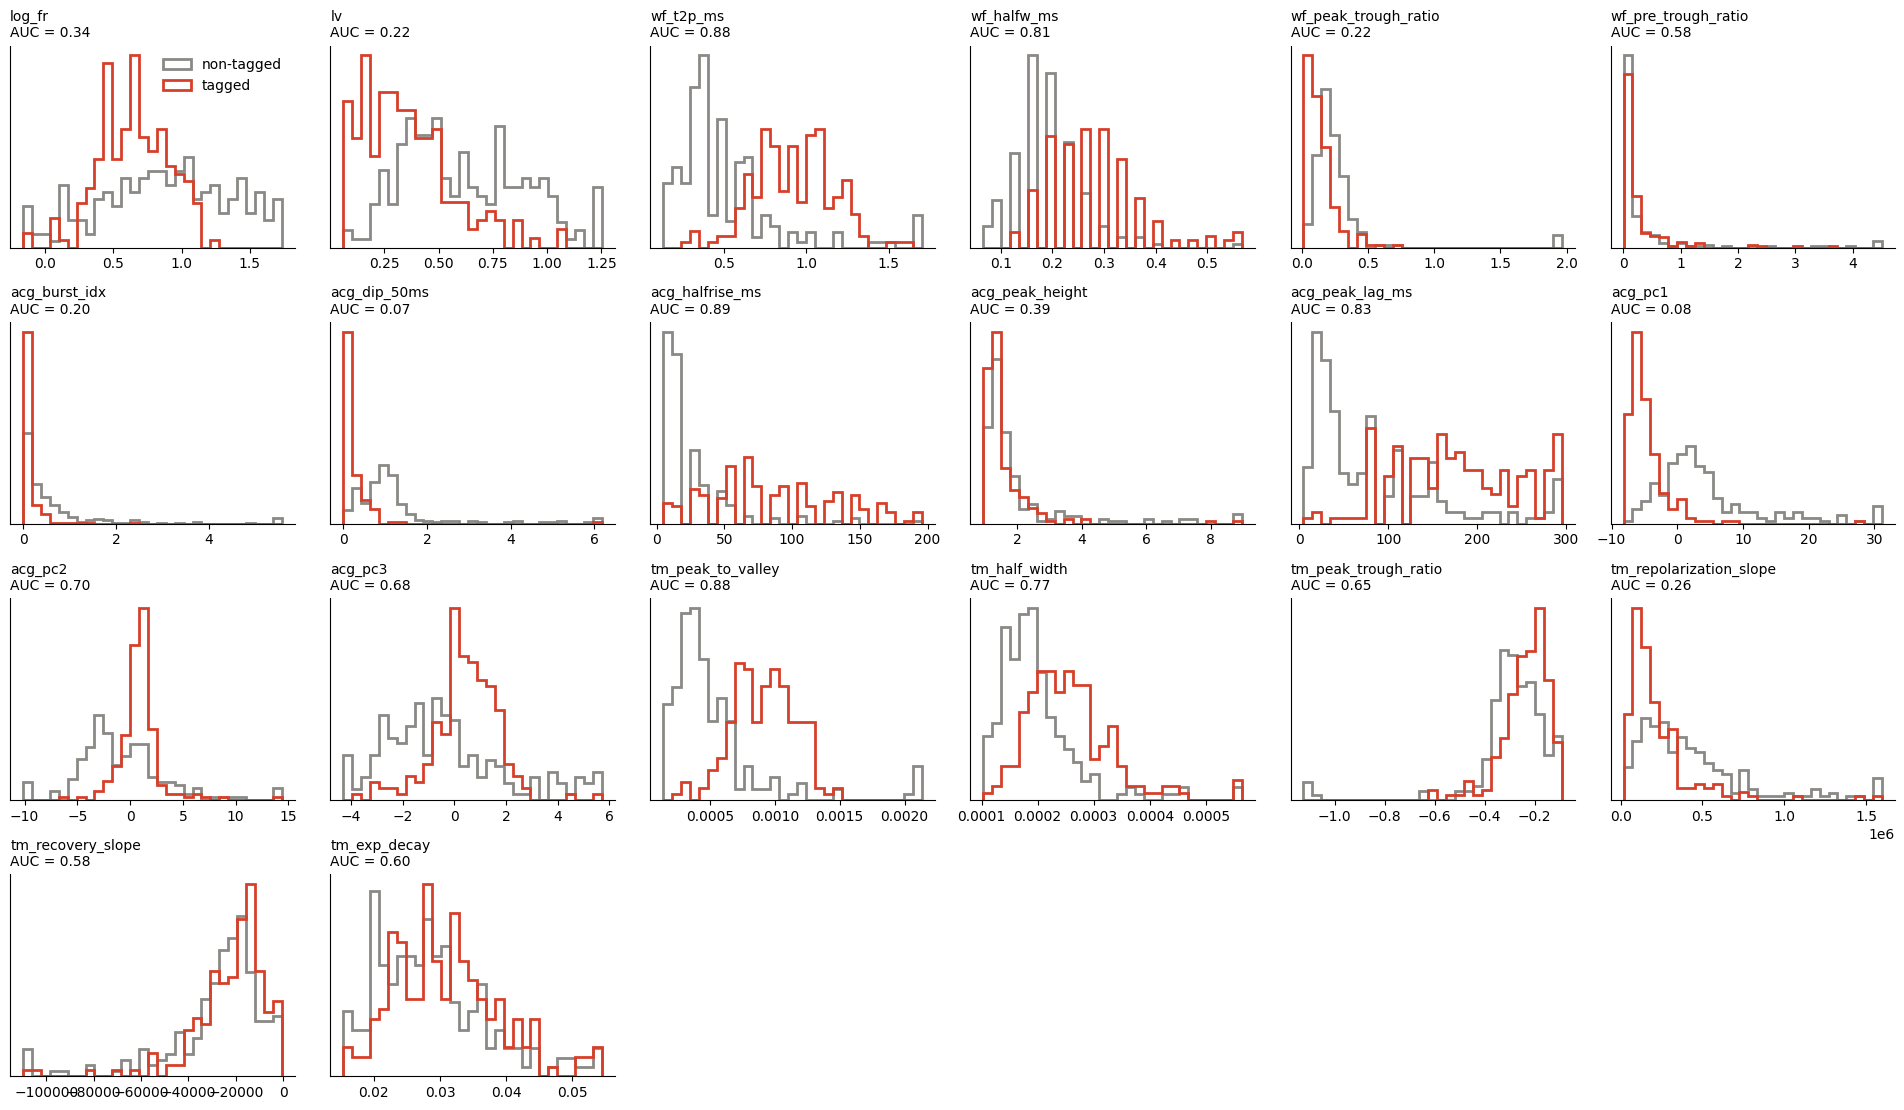

In [3]:
def univariate(feat, cols):
    t = feat['tagged'].to_numpy()
    out = []
    for c in cols:
        a, b = feat.loc[t, c].dropna(), feat.loc[~t, c].dropna()
        res = mannwhitneyu(a, b)
        out.append({'feature': c, 'median_tagged': a.median(), 'median_non_tagged': b.median(),
                    'auc': res.statistic / (len(a) * len(b)), 'p': res.pvalue})
    return pd.DataFrame(out).set_index('feature')


def plot_hists(feat, cols, uni, ncol=6):
    t = feat['tagged'].to_numpy()
    nrow = int(np.ceil(len(cols) / ncol))
    fig, axes = plt.subplots(nrow, ncol, figsize=(3.2 * ncol, 2.8 * nrow))
    axes = axes.ravel()
    for ax, c in zip(axes, cols):
        lo, hi = np.nanpercentile(feat[c], [1, 99])
        edges = np.linspace(lo, hi, 30)
        for g, col, lab in [(False, NONTAGGED_COLOR, 'non-tagged'), (True, TAGGED_COLOR, 'tagged')]:
            ax.hist(np.clip(feat.loc[t == g, c].dropna(), lo, hi), edges, density=True, histtype='step',
                    lw=2, color=col, label=lab)
        ax.set_title(f"{c}\nAUC = {uni.loc[c, 'auc']:.2f}", fontsize=10, loc='left')
        ax.spines[['top', 'right']].set_visible(False)
        ax.set_yticks([])
    axes[0].legend(frameon=False)
    for ax in axes[len(cols):]:
        ax.axis('off')
    fig.tight_layout()


uni = univariate(feat, ALL_FEATS)
display(uni.style.format({'median_tagged': '{:.3g}', 'median_non_tagged': '{:.3g}', 'auc': '{:.2f}', 'p': '{:.1e}'}))
plot_hists(feat, ALL_FEATS, uni)

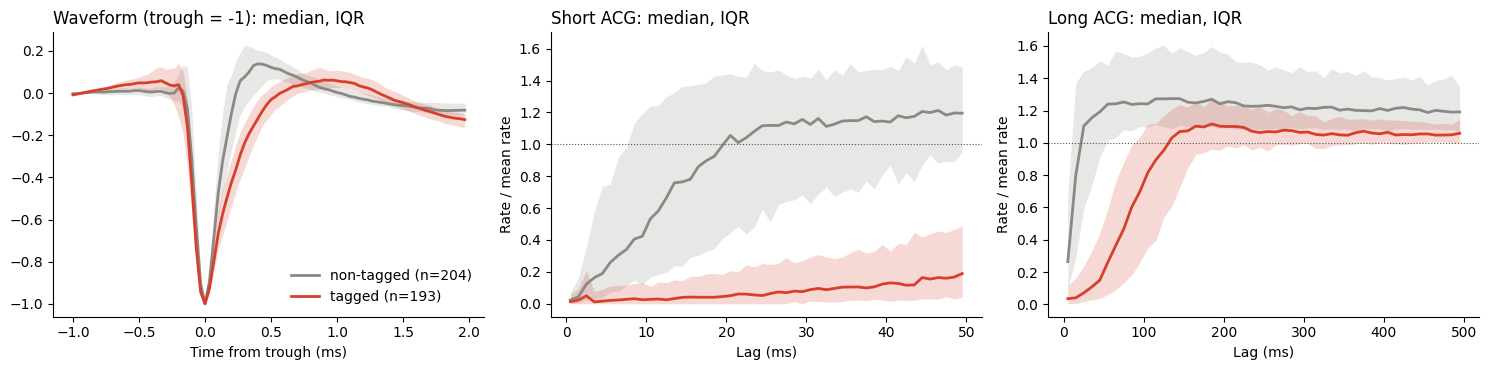

In [4]:
def plot_shapes(pop, title_suffix=''):
    t = pop['feat']['tagged'].to_numpy()
    wfs = pop['wf']
    t_wf = (np.arange(wfs.shape[1]) - np.argmin(np.nanmedian(wfs, 0))) / FS * 1000
    fig, axes = plt.subplots(1, 3, figsize=(15, 3.8))
    for ax, x, M, xlabel, title in [
            (axes[0], t_wf, wfs, 'Time from trough (ms)', 'Waveform (trough = -1)'),
            (axes[1], LAG_SHORT_MS, pop['acg_short'], 'Lag (ms)', 'Short ACG'),
            (axes[2], LAG_LONG_MS, pop['acg_long'], 'Lag (ms)', 'Long ACG')]:
        for g, col, lab in [(False, NONTAGGED_COLOR, 'non-tagged'), (True, TAGGED_COLOR, 'tagged')]:
            q25, med, q75 = np.nanpercentile(M[t == g], [25, 50, 75], axis=0)
            ax.fill_between(x, q25, q75, color=col, alpha=0.2, lw=0)
            ax.plot(x, med, color=col, lw=2, label=f'{lab} (n={np.sum(t == g)})')
        if M is not wfs:
            ax.axhline(1, color='#52514e', lw=0.8, ls=':')
            ax.set_ylabel('Rate / mean rate')
        ax.set_xlabel(xlabel)
        ax.set_title(f'{title}: median, IQR{title_suffix}', loc='left')
        ax.spines[['top', 'right']].set_visible(False)
    axes[0].legend(frameon=False)
    fig.tight_layout()


plot_shapes(pops['matched'])

### ACG PCA
PCA of the whole ACG shape, fit on the population without labels. The input for each unit is:
1. the short ACG (0–50 ms, 1 ms bins), followed by the long ACG beyond 50 ms (10 ms bins);
2. clipped to `[0, ACG_PCA_CLIP]`;
3. with each bin standardized across units.

The loadings show which part of the ACG each PC weights. A PC that loads on the first ~100 ms captures the post-spike trough that separates the tagged units.

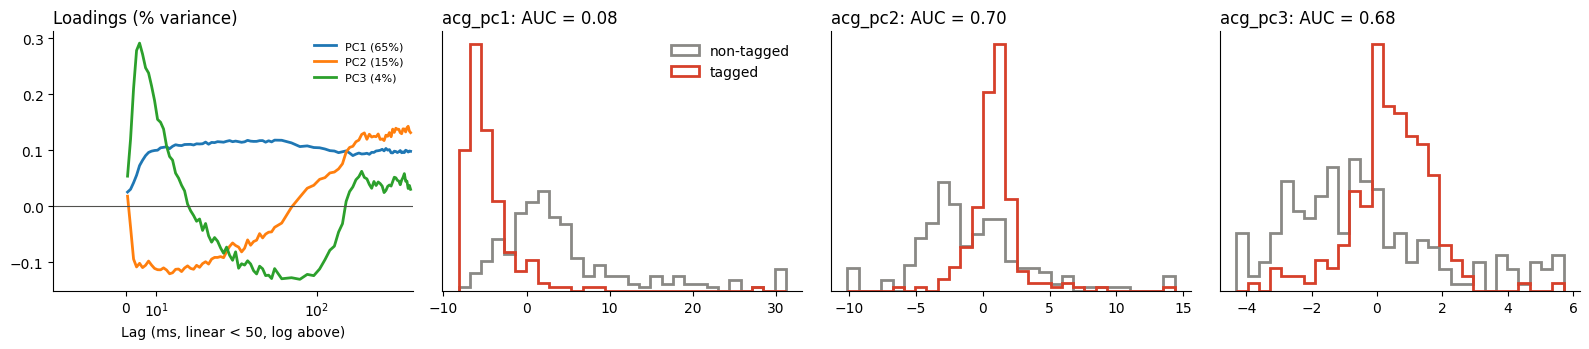

In [5]:
def plot_acg_pca(pop):
    pca, feat = pop['acg_pca'], pop['feat']
    t = feat['tagged'].to_numpy()
    lag = np.concatenate([LAG_SHORT_MS, LAG_LONG_MS[LAG_LONG_MS > 50]])
    fig, axes = plt.subplots(1, 1 + N_ACG_PCS, figsize=(4 * (1 + N_ACG_PCS), 3.6))
    for i in range(N_ACG_PCS):
        axes[0].plot(lag, pca.components_[i], lw=2, label=f'PC{i + 1} ({100 * pca.explained_variance_ratio_[i]:.0f}%)')
    axes[0].axhline(0, color='#52514e', lw=0.8)
    axes[0].set_xscale('symlog', linthresh=50)
    axes[0].set_xlabel('Lag (ms, linear < 50, log above)')
    axes[0].set_title('Loadings (% variance)', loc='left')
    axes[0].legend(frameon=False, fontsize=8)
    for ax, c in zip(axes[1:], ACG_PC_COLS):
        edges = np.linspace(*np.nanpercentile(feat[c], [1, 99]), 30)
        for g, col, lab in [(False, NONTAGGED_COLOR, 'non-tagged'), (True, TAGGED_COLOR, 'tagged')]:
            ax.hist(np.clip(feat.loc[t == g, c], edges[0], edges[-1]), edges, density=True, histtype='step',
                    lw=2, color=col, label=lab)
        a, b = feat.loc[t, c], feat.loc[~t, c]
        ax.set_title(f'{c}: AUC = {mannwhitneyu(a, b).statistic / (len(a) * len(b)):.2f}', loc='left')
        ax.set_yticks([])
    for ax in axes:
        ax.spines[['top', 'right']].set_visible(False)
    axes[1].legend(frameon=False)
    fig.tight_layout()


plot_acg_pca(pops['matched'])

### LV vs. ACG shape
LV should track ACG shape (a deep, long post-spike trough means regular firing), but not perfectly. Spearman correlations are computed across all units.

,log_fr,lv,wf_t2p_ms,wf_halfw_ms,wf_peak_trough_ratio,wf_pre_trough_ratio,acg_burst_idx,acg_dip_50ms,acg_halfrise_ms,acg_peak_height,acg_peak_lag_ms,acg_pc1,acg_pc2,acg_pc3,tm_peak_to_valley,tm_half_width,tm_peak_trough_ratio,tm_repolarization_slope,tm_recovery_slope,tm_exp_decay
lv,-0.21,1.00,-0.40,-0.32,0.20,-0.06,0.67,0.73,-0.70,0.15,-0.34,0.70,-0.34,-0.04,-0.41,-0.28,-0.07,0.23,0.02,-0.20


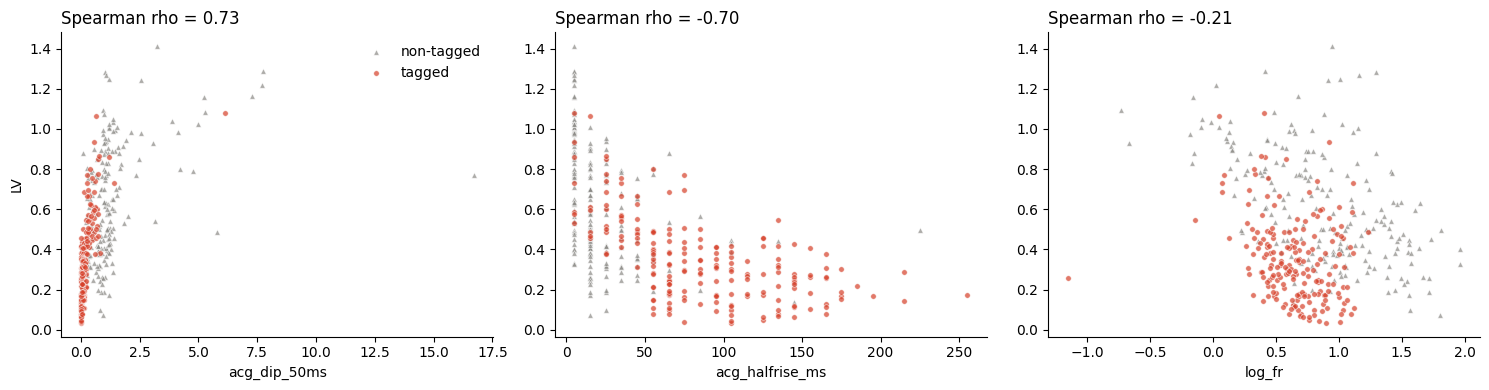

In [6]:
rho = feat[ALL_FEATS].corr(method='spearman')
display(rho[['lv']].T.style.format('{:.2f}').background_gradient(cmap='RdBu_r', vmin=-1, vmax=1, axis=None))
fig, axes = plt.subplots(1, 3, figsize=(15, 4))
for ax, c in zip(axes, ['acg_dip_50ms', 'acg_halfrise_ms', 'log_fr']):
    for g, col, lab in [(False, NONTAGGED_COLOR, 'non-tagged'), (True, TAGGED_COLOR, 'tagged')]:
        m = is_tag == g
        ax.scatter(feat.loc[m, c], feat.loc[m, 'lv'], s=16, color=col, marker=GROUP_MARKERS[g], alpha=0.7,
                   lw=0.5, edgecolor='white', label=lab)
    ax.set_xlabel(c)
    ax.set_title(f"Spearman rho = {rho.loc['lv', c]:.2f}", loc='left')
    ax.spines[['top', 'right']].set_visible(False)
axes[0].set_ylabel('LV')
axes[0].legend(frameon=False)
fig.tight_layout()

### Clustering
For each feature set:
1. Transform the features: Yeo-Johnson, explained below, or z-score.
2. Fit k-means (k = 2).
3. Fit the mclust-style EM.

The **tagged-like** cluster is whichever cluster holds the larger fraction of tagged units. Each fit is scored on four metrics:
* **ARI:** adjusted Rand index against the labels; 0 = chance, 1 = identical.
* **Recall:** the fraction of tagged units in the tagged-like cluster.
* **Precision:** the fraction of the tagged-like cluster that is tagged.
* **non-tagged in:** the fraction of non-tagged units in the tagged-like cluster.

#### Why the Yeo-Johnson transform
Both k-means and a Gaussian mixture assume, implicitly or explicitly, that each cluster is a roughly symmetric blob. Several features here are strongly right-skewed, with long tails of a few extreme units: burst index, the ACG dip, ratios, and slopes. On raw z-scores, EM tends to spend one of its two components on that tail, isolating a handful of outliers instead of finding the tagged/non-tagged split. In an earlier version, the ARI on all features was about 0.03 without the transform and about 0.34 with it.

Yeo-Johnson (Yeo & Johnson 2000) is a per-feature power transform that makes each feature as close to normal as possible. For a value $x$ and a parameter $\lambda$:

$$
\psi(x, \lambda) =
\begin{cases}
\dfrac{(x + 1)^{\lambda} - 1}{\lambda} & x \ge 0,\ \lambda \ne 0 \\
\log(x + 1) & x \ge 0,\ \lambda = 0 \\
-\dfrac{(1 - x)^{2 - \lambda} - 1}{2 - \lambda} & x < 0,\ \lambda \ne 2 \\
-\log(1 - x) & x < 0,\ \lambda = 2
\end{cases}
$$

* **How λ is chosen:** separately for each feature, by maximum likelihood, so the transformed feature is as Gaussian as possible. The result is then z-scored (`sklearn.preprocessing.PowerTransformer`).
* **What λ does:** λ < 1 compresses the right tail, like a log or square root. λ > 1 stretches it. λ = 1 leaves the feature unchanged apart from a shift.
* **Why Yeo-Johnson rather than Box-Cox:** Yeo-Johnson also handles zero and negative values, such as PCs, slopes, and ACG bins of 0.
* **What it preserves:** it is monotonic, so it keeps each unit's rank on every feature; it only changes the spacing between units.
* **Labels are not involved:** λ is fit on the pooled population, which can be a real bimodal mixture, so the transform makes the data more Gaussian overall but cannot remove that bimodality.

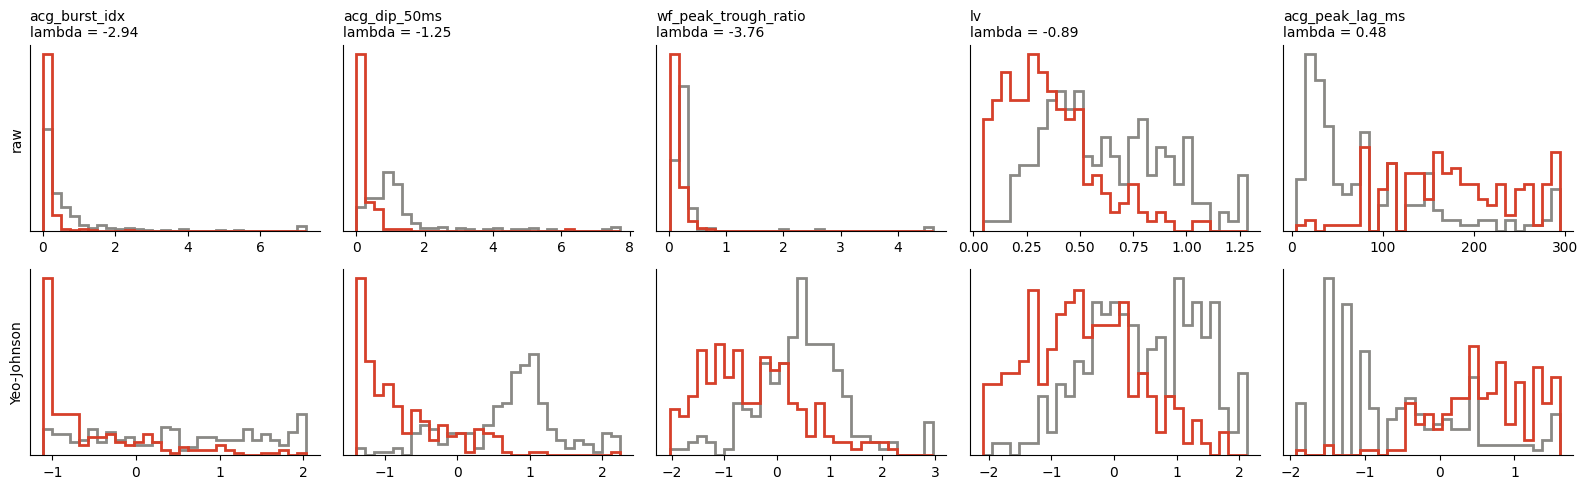

In [7]:
def show_transform(feat, cols):
    pt = PowerTransformer().fit(feat[cols].dropna())
    fig, axes = plt.subplots(2, len(cols), figsize=(3.2 * len(cols), 5))
    Z = pt.transform(feat[cols].fillna(feat[cols].median()))
    t = feat['tagged'].to_numpy()
    for j, c in enumerate(cols):
        for row, x in enumerate([feat[c].to_numpy(), Z[:, j]]):
            ax = axes[row, j]
            lo, hi = np.nanpercentile(x, [0.5, 99.5])
            edges = np.linspace(lo, hi, 30)
            for g, col in [(False, NONTAGGED_COLOR), (True, TAGGED_COLOR)]:
                ax.hist(np.clip(x[t == g], lo, hi), edges, histtype='step', lw=2, color=col)
            ax.set_yticks([])
            ax.spines[['top', 'right']].set_visible(False)
        axes[0, j].set_title(f'{c}\nlambda = {pt.lambdas_[j]:.2f}', loc='left', fontsize=10)
    axes[0, 0].set_ylabel('raw')
    axes[1, 0].set_ylabel('Yeo-Johnson')
    fig.tight_layout()


show_transform(feat, ['acg_burst_idx', 'acg_dip_50ms', 'wf_peak_trough_ratio', 'lv', 'acg_peak_lag_ms'])

In [8]:
def transform(X):
    if TRANSFORM == 'yeo-johnson':
        return PowerTransformer(method='yeo-johnson').fit_transform(X)
    return StandardScaler().fit_transform(X)


def fit_kmeans(X):
    km = KMeans(n_clusters=2, n_init=50, random_state=SEED).fit(X)
    d = km.transform(X)  # distance to each centroid
    return km.labels_, d


def fit_em(X):
    """mclust-like: 2-component GMMs initialized from a Ward hierarchical partition, one per
    covariance parameterization; returns labels, posteriors, the winning model and every BIC."""
    hc = AgglomerativeClustering(n_clusters=2, linkage='ward').fit_predict(X)
    means = np.stack([X[hc == k].mean(0) for k in range(2)])
    weights = np.bincount(hc, minlength=2) / len(hc)
    models = {ct: GaussianMixture(2, covariance_type=ct, means_init=means, weights_init=weights,
                                  max_iter=1000, random_state=SEED).fit(X) for ct in COV_TYPES}
    bic = {ct: m.bic(X) for ct, m in models.items()}  # lower is better in sklearn
    best = min(bic, key=bic.get)
    return models[best].predict(X), models[best].predict_proba(X), best, bic


def tagged_like(y, lab):
    return int(np.argmax([y[lab == c].mean() if np.any(lab == c) else -1 for c in range(2)]))


def score(y, lab):
    k = tagged_like(y, lab)
    p = lab == k
    return {'ARI': adjusted_rand_score(y, lab), 'recall': p[y].mean(), 'precision': y[p].mean(),
            'non-tagged in': p[~y].mean(), 'tagged-like n': p.sum()}


def run_clustering(feat, sets, center_sessions=False):
    """k-means and EM per feature set. Each fit keeps a continuous 'tagged-like' score per unit
    (EM posterior; k-means distance margin) for the within-session checks."""
    results, fits = [], {}
    for name, cols in sets.items():
        d = feat.dropna(subset=cols)
        Xraw = d[cols].to_numpy(dtype=float)
        if center_sessions:
            Xraw = Xraw - d.groupby('session')[cols].transform('median').to_numpy(dtype=float)
        X = transform(Xraw)
        y = d['tagged'].to_numpy()
        km, dist = fit_kmeans(X)
        em, post, cov, bic = fit_em(X)
        k_km, k_em = tagged_like(y, km), tagged_like(y, em)
        fits[name] = {'index': d.index, 'X': X, 'y': y, 'session': d['session'].to_numpy(),
                      'kmeans': km, 'em': em, 'cov': cov, 'bic': bic,
                      'score_kmeans': dist[:, 1 - k_km] - dist[:, k_km], 'score_em': post[:, k_em]}
        for method, lab in [('k-means', km), ('EM', em)]:
            results.append({'features': name, 'method': method, 'cov': cov if method == 'EM' else '',
                            'n': len(y), **score(y, lab)})
    return pd.DataFrame(results), fits


FMT = {c: '{:.2f}' for c in ['ARI', 'recall', 'precision', 'non-tagged in']}
results, fits = run_clustering(feat, FEATURE_SETS)
display(results.style.format(FMT).hide(axis='index'))
print('Chance precision (fraction tagged):', f'{is_tag.mean():.2f}')

features,method,cov,n,ARI,recall,precision,non-tagged in,tagged-like n
firing rate,k-means,,397,0.08,0.73,0.61,0.44,230
firing rate,EM,tied,397,0.10,0.95,0.59,0.62,311
LV,k-means,,397,0.14,0.76,0.66,0.37,222
LV,EM,tied,397,0.13,0.84,0.63,0.47,257
waveform,k-means,,397,0.47,0.94,0.78,0.25,231
waveform,EM,full,397,0.42,0.82,0.82,0.17,193
ACG,k-means,,397,0.43,0.93,0.77,0.27,235
ACG,EM,full,397,0.46,0.84,0.83,0.16,196
ACG PCs,k-means,,397,0.44,0.89,0.80,0.22,215
ACG PCs,EM,full,397,0.44,0.80,0.84,0.14,184


Chance precision (fraction tagged): 0.49


#### EM model selection (BIC per covariance parameterization; lower is better)

In [9]:
bic_tbl = pd.DataFrame({name: f['bic'] for name, f in fits.items()}).T
bic_tbl['selected'] = [f['cov'] for f in fits.values()]
display(bic_tbl.style.format({ct: '{:.0f}' for ct in COV_TYPES}).highlight_min(axis=1, subset=COV_TYPES, color='#dfe9f7'))

,spherical,diag,tied,full,selected
firing rate,1155,1155,1151,1155,tied
LV,1140,1140,1139,1140,tied
waveform,4345,4291,4204,4025,full
ACG,4811,4573,4065,3666,full
ACG PCs,3347,2810,3335,2766,full
ACG + LV,5786,5554,4841,4384,full
ACG PCs + LV,4483,3748,4199,3569,full
waveform + ACG + LV,10056,9736,8900,8544,full
all,11121,10757,9536,9122,full
template metrics,6360,6231,5470,5215,full


#### Cluster assignments in feature space (PCA of the transformed feature set)

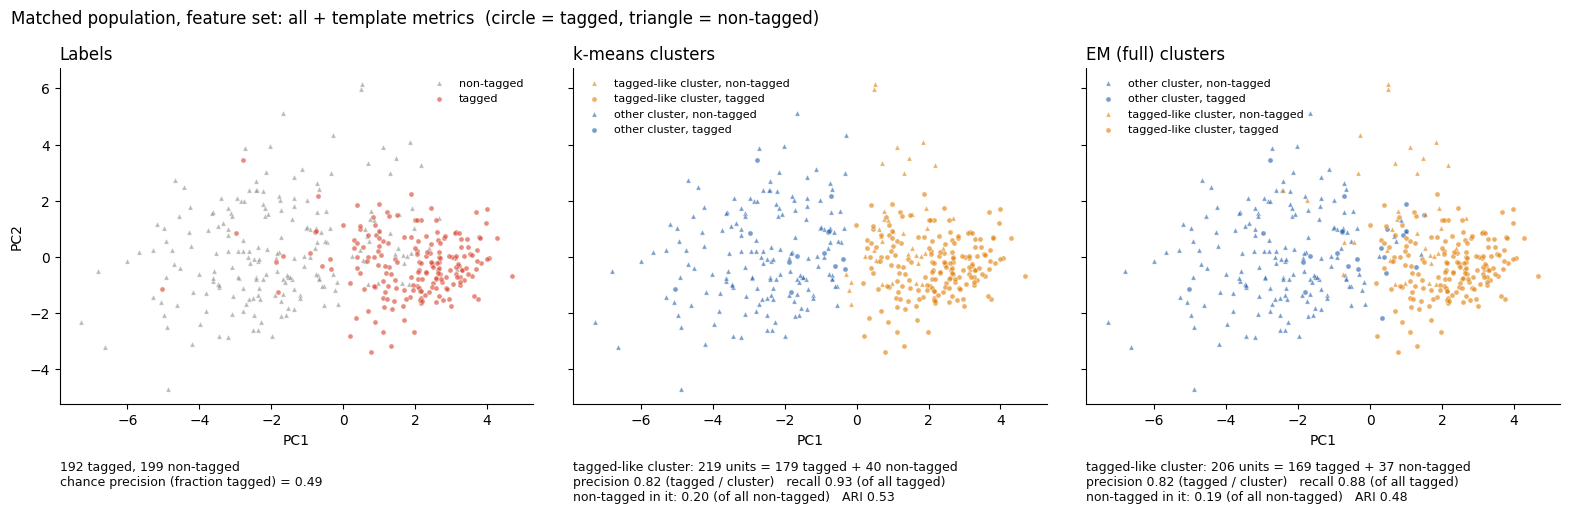

In [10]:
def plot_clusters(f, title, other_label='non-tagged'):
    """PCA view of the labels and of each method's clusters, with the cluster-vs-label counts
    written under each panel."""
    pcs = PCA(n_components=2, random_state=SEED).fit_transform(f['X'])
    y = f['y']
    fig, axes = plt.subplots(1, 3, figsize=(16, 5.8), sharex=True, sharey=True)
    for g, col, lab in [(False, NONTAGGED_COLOR, other_label), (True, TAGGED_COLOR, 'tagged')]:
        m = y == g
        axes[0].scatter(pcs[m, 0], pcs[m, 1], s=14, color=col, marker=GROUP_MARKERS[g], alpha=0.6,
                        lw=0.5, edgecolor='white', label=lab)
    axes[0].set_title('Labels', loc='left')
    notes = [f'{y.sum()} tagged, {(~y).sum()} {other_label}\n'
             f'chance precision (fraction tagged) = {y.mean():.2f}']
    for ax, method, name in [(axes[1], 'kmeans', 'k-means'), (axes[2], 'em', f"EM ({f['cov']})")]:
        k = tagged_like(y, f[method])
        for c in range(2):
            for g in [False, True]:
                m = (f[method] == c) & (y == g)
                ax.scatter(pcs[m, 0], pcs[m, 1], s=14, color=CLUSTER_COLORS[int(c == k)], marker=GROUP_MARKERS[g],
                           alpha=0.6, lw=0.5, edgecolor='white',
                           label=f"{'tagged-like' if c == k else 'other'} cluster, {'tagged' if g else other_label}")
        ax.set_title(f'{name} clusters', loc='left')
        p = f[method] == k
        n_t, n_o = int((p & y).sum()), int((p & ~y).sum())
        notes.append(f'tagged-like cluster: {p.sum()} units = {n_t} tagged + {n_o} {other_label}\n'
                     f'precision {n_t / max(p.sum(), 1):.2f} (tagged / cluster)   '
                     f'recall {n_t / y.sum():.2f} (of all tagged)\n'
                     f'{other_label} in it: {n_o / (~y).sum():.2f} (of all {other_label})   '
                     f'ARI {adjusted_rand_score(y, f[method]):.2f}')
    for ax, note in zip(axes, notes):
        ax.set_xlabel('PC1')
        ax.spines[['top', 'right']].set_visible(False)
        ax.legend(frameon=False, fontsize=8)
        ax.text(0, -0.17, note, transform=ax.transAxes, ha='left', va='top', fontsize=9, color='#0b0b0b')
    axes[0].set_ylabel('PC2')
    fig.suptitle(f'{title}  (circle = tagged, triangle = {other_label})', x=0.01, ha='left')
    fig.tight_layout()
    fig.subplots_adjust(bottom=0.3)


SHOW = 'all + template metrics' if 'all + template metrics' in fits else 'all'
plot_clusters(fits[SHOW], f'Matched population, feature set: {SHOW}')

#### What the AUC means, graphically
The AUC answers one question: **pick one tagged and one non-tagged unit at random; how often does the tagged one get the higher score?** The score here is the session-held-out output of the supervised model on the same feature set, so every unit is scored by a model that never saw its session.
* **1st panel:** the score distributions of the two groups, each scaled to the same area so their *shapes* can be compared. The less they overlap, the higher the AUC. The dashed line is the 0.5 threshold.
* **2nd panel:** the same scores as **raw counts**. When one group is much larger, a thin tail in the 1st panel can still be many units; everything right of the threshold is what the model would call tagged. Bins taller than the axis are clipped and labeled with their count.
* **3rd panel:** every (tagged, non-tagged) pair as one cell, with both axes sorted by score. A cell is red where the tagged unit scored higher. **The red fraction of the square is the AUC.** AUC 0.5 would fill half the square (a coin flip); AUC 1 would fill all of it. The red/gray boundary is the ROC curve.
* **4th panel:** all units ranked by score, with one tick per tagged unit. A high AUC means the ticks pile up at the top of the ranking. The black line shows the fraction of tagged units found going down the ranking, between a random ranking (dotted) and a perfect one (dashed).

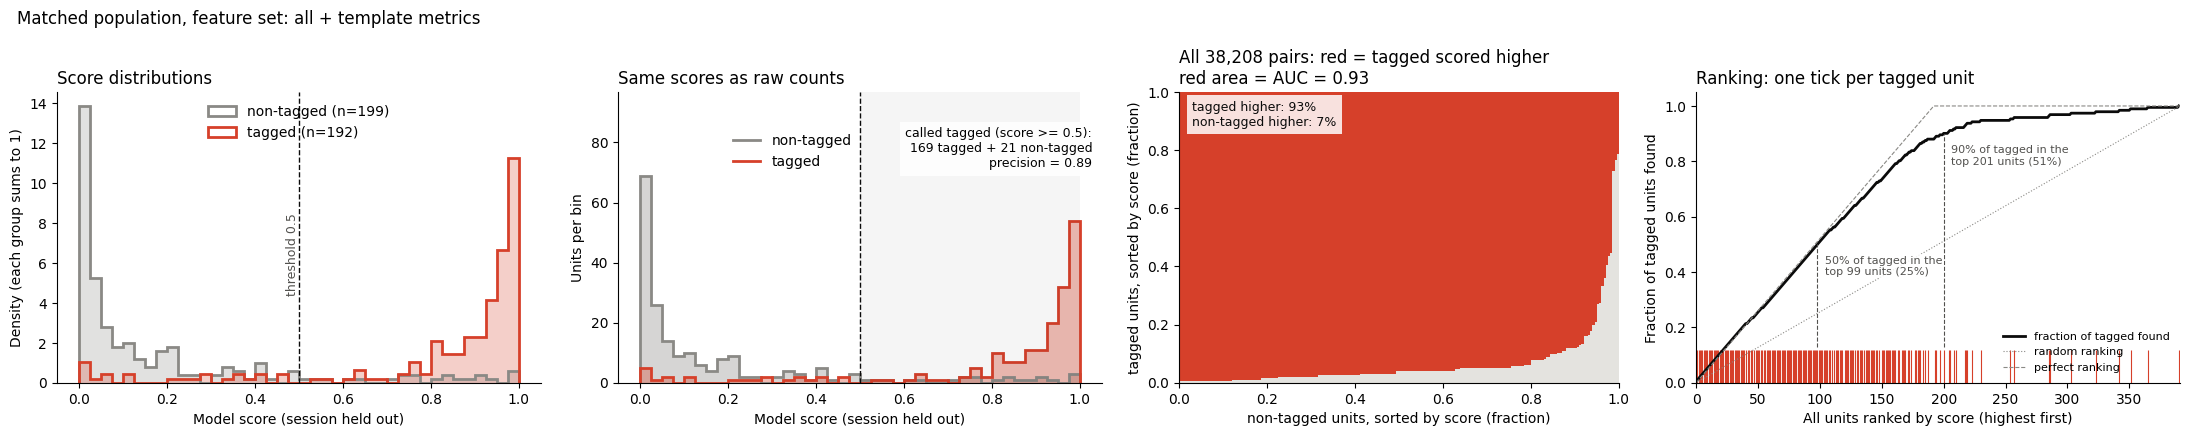

In [11]:
def cv_scores(feat, cols):
    d = feat.dropna(subset=cols)
    y = d['tagged'].to_numpy()
    clf = make_pipeline(PowerTransformer(), LogisticRegression(max_iter=2000, class_weight='balanced'))
    cv = StratifiedGroupKFold(n_splits=5, shuffle=True, random_state=SEED)
    p = cross_val_predict(clf, d[cols].to_numpy(), y.astype(int), cv=cv, groups=d['session'], method='predict_proba')[:, 1]
    return y, p


def plot_auc_intuition(y, score, title, other_label='non-tagged', threshold=0.5):
    y = np.asarray(y, bool)
    st, sn = np.sort(score[y]), np.sort(score[~y])
    auc = roc_auc_score(y, score)
    fig, axes = plt.subplots(1, 4, figsize=(22, 4.4), gridspec_kw={'width_ratios': [1.1, 1.1, 1, 1.1]})

    ax = axes[0]
    edges = np.linspace(0, 1, 41)
    for vals, col, lab in [(sn, NONTAGGED_COLOR, other_label), (st, TAGGED_COLOR, 'tagged')]:
        ax.hist(vals, edges, density=True, histtype='stepfilled', alpha=0.25, color=col)
        ax.hist(vals, edges, density=True, histtype='step', lw=2, color=col, label=f'{lab} (n={len(vals)})')
    ax.axvline(threshold, color='#0b0b0b', lw=1, ls='--')
    ax.text(threshold, 0.3, f'threshold {threshold} ', transform=ax.get_xaxis_transform(), rotation=90,
            ha='right', va='bottom', fontsize=9, color='#52514e')
    ax.set_xlabel('Model score (session held out)')
    ax.set_ylabel('Density (each group sums to 1)')
    ax.set_title('Score distributions', loc='left')
    ax.legend(frameon=False, loc='upper center')

    # raw counts: same bins, not normalized, so the larger group's tail shows at its real size.
    # The y-axis is capped at the tallest tagged bin; taller bins are clipped and labeled.
    ax = axes[1]
    cn, _ = np.histogram(sn, edges)
    ct, _ = np.histogram(st, edges)
    cap = 1.6 * ct.max()
    centers = (edges[:-1] + edges[1:]) / 2
    w = np.diff(edges)
    ax.bar(centers, np.minimum(cn, cap), w, color=NONTAGGED_COLOR, alpha=0.35, lw=0)
    ax.bar(centers, ct, w, color=TAGGED_COLOR, alpha=0.35, lw=0)
    ax.stairs(np.minimum(cn, cap), edges, color=NONTAGGED_COLOR, lw=2, label=other_label)
    ax.stairs(ct, edges, color=TAGGED_COLOR, lw=2, label='tagged')
    clipped = cn > cap
    if clipped.any():
        ax.text(edges[:-1][clipped][0], cap * 1.01, 'clipped: ' + ', '.join(str(c) for c in cn[clipped]) + ' units',
                ha='left', va='bottom', fontsize=8, color='#52514e')
    ax.set_ylim(0, cap * 1.12)
    ax.axvline(threshold, color='#0b0b0b', lw=1, ls='--')
    ax.axvspan(threshold, 1, color='#0b0b0b', alpha=0.04, lw=0)
    n_t, n_o = int(np.sum(st >= threshold)), int(np.sum(sn >= threshold))
    ax.text(0.98, 0.88, f'called tagged (score >= {threshold}):\n{n_t} tagged + {n_o} {other_label}\n'
            f'precision = {n_t / max(n_t + n_o, 1):.2f}', transform=ax.transAxes, ha='right', va='top', fontsize=9,
            bbox=dict(facecolor='white', edgecolor='none', alpha=0.85))
    ax.set_xlabel('Model score (session held out)')
    ax.set_ylabel('Units per bin')
    ax.set_title('Same scores as raw counts', loc='left')
    ax.legend(frameon=False, loc='upper center', bbox_to_anchor=(0.36, 0.9))

    # every pair: rows = tagged (sorted), columns = other (sorted); 1 where tagged scores higher
    ax = axes[2]
    wins = (st[:, None] > sn[None, :]).astype(float) + 0.5 * (st[:, None] == sn[None, :])
    from matplotlib.colors import ListedColormap
    ax.imshow(wins, aspect='auto', origin='lower', cmap=ListedColormap(['#e4e3df', '#f0a99c', TAGGED_COLOR]),
              vmin=0, vmax=1, extent=[0, 1, 0, 1], interpolation='nearest')
    ax.set_xlabel(f'{other_label} units, sorted by score (fraction)')
    ax.set_ylabel('tagged units, sorted by score (fraction)')
    ax.set_title(f'All {len(st) * len(sn):,} pairs: red = tagged scored higher\nred area = AUC = {auc:.2f}', loc='left')
    ax.text(0.03, 0.97, f'tagged higher: {wins.mean():.0%}\n{other_label} higher: {1 - wins.mean():.0%}',
            ha='left', va='top', fontsize=9, color='#0b0b0b',
            bbox=dict(facecolor='white', edgecolor='none', alpha=0.85))

    ax = axes[3]
    order = np.argsort(-score)
    ranked = y[order]
    pos = np.flatnonzero(ranked)
    ax.vlines(pos, 0, 0.12, color=TAGGED_COLOR, lw=0.8)
    found = np.cumsum(ranked) / y.sum()
    ax.plot(np.arange(len(y)), found, color='#0b0b0b', lw=2, label='fraction of tagged found')
    ax.plot([0, len(y)], [0, 1], color='#8a8985', lw=0.8, ls=':', label='random ranking')
    ax.plot([0, y.sum(), len(y)], [0, 1, 1], color='#8a8985', lw=0.8, ls='--', label='perfect ranking')
    for frac in [0.5, 0.9]:
        k = int(np.searchsorted(found, frac))
        ax.plot([k, k], [0.13, frac], color='#52514e', lw=0.8, ls='--')
        ax.text(k + 0.015 * len(y), frac - 0.04, f'{frac:.0%} of tagged in the\ntop {k + 1} units ({(k + 1) / len(y):.0%})',
                fontsize=8, color='#52514e', ha='left', va='top',
                bbox=dict(facecolor='white', edgecolor='none', alpha=0.85, pad=1))
    ax.set_xlim(0, len(y))
    ax.set_ylim(0, 1.05)
    ax.set_xlabel('All units ranked by score (highest first)')
    ax.set_ylabel('Fraction of tagged units found')
    ax.set_title('Ranking: one tick per tagged unit', loc='left')
    ax.legend(frameon=False, loc='lower right', fontsize=8)
    for ax in axes:
        ax.spines[['top', 'right']].set_visible(False)
    fig.suptitle(title, x=0.01, ha='left')
    fig.tight_layout()


y_m, p_m = cv_scores(feat, FEATURE_SETS[SHOW])
plot_auc_intuition(y_m, p_m, f'Matched population, feature set: {SHOW}')

### Within-session check
Session (probe, insertion, drift, sorting quality) could drive the clustering instead of cell type. Three checks:

1. **Per-session AUC.** Within each session that has ≥ `MIN_PER_GROUP` units of each group, the AUC of the unit's continuous tagged-like score, tagged vs non-tagged. The score is the EM posterior of the tagged-like component, or the k-means distance margin. Reported as the median over sessions and the fraction of sessions with AUC > 0.5. In the matched population, the **paired** version also compares each tagged unit with its own matched control from the same insertion.
2. **Within-session shuffle null for ARI.** Shuffle the labels within each session, keeping every session's tagged count, and recompute the ARI of the same clustering. The p-value is the fraction of shuffles with ARI ≥ the observed value. If session composition alone explained the clusters, the observed ARI would sit inside this null.
3. **Session-centered features.** Subtract each session's median from every feature before transforming and clustering. This removes any session-wide offset. If ARI holds up, the split is not driven by between-session differences.

In [12]:
def within_session(fits, feat, pairs=None):
    rows = []
    for name, f in fits.items():
        for method in ['kmeans', 'em']:
            score_ = f[f'score_{method}']
            aucs = []
            for s in np.unique(f['session']):
                m = f['session'] == s
                y = f['y'][m]
                if y.sum() >= MIN_PER_GROUP and (~y).sum() >= MIN_PER_GROUP:
                    aucs.append(roc_auc_score(y, score_[m]))
            obs = adjusted_rand_score(f['y'], f[method])
            null = np.empty(N_SHUFFLE)
            y_sh = f['y'].copy()
            groups = [np.flatnonzero(f['session'] == s) for s in np.unique(f['session'])]
            for i in range(N_SHUFFLE):
                for idx in groups:
                    y_sh[idx] = RNG.permutation(f['y'][idx])
                null[i] = adjusted_rand_score(y_sh, f[method])
            row = {'features': name, 'method': 'k-means' if method == 'kmeans' else 'EM',
                   'ARI': obs, 'ARI null 95%': np.percentile(null, 95),
                   'p (within-session shuffle)': (np.sum(null >= obs) + 1) / (N_SHUFFLE + 1),
                   'sessions': len(aucs), 'median session AUC': np.median(aucs) if aucs else np.nan,
                   'sessions AUC > 0.5': np.mean(np.array(aucs) > 0.5) if aucs else np.nan}
            if pairs is not None:
                key = pd.Series(score_, index=pd.MultiIndex.from_frame(feat.loc[f['index'], ['session', 'unit']]))
                p = pairs[pairs.set_index(['session', 'unit']).index.isin(key.index)
                          & pairs.set_index(['session', 'matched_tagged_unit']).index.isin(key.index)]
                ctrl = key.loc[list(zip(p['session'], p['unit']))].to_numpy()
                tag = key.loc[list(zip(p['session'], p['matched_tagged_unit']))].to_numpy()
                row['pairs'] = len(p)
                row['pairs tagged > control'] = np.mean(tag > ctrl)
            rows.append(row)
    return pd.DataFrame(rows)


pairs = units.loc[units['matched'], ['session', 'unit', 'matched_tagged_unit']].astype({'matched_tagged_unit': int})
ws = within_session(fits, feat, pairs)
display(ws.style.format({'ARI': '{:.2f}', 'ARI null 95%': '{:.3f}', 'p (within-session shuffle)': '{:.3f}',
                         'median session AUC': '{:.2f}', 'sessions AUC > 0.5': '{:.2f}',
                         'pairs tagged > control': '{:.2f}'}).hide(axis='index'))

res_c, _ = run_clustering(feat, FEATURE_SETS, center_sessions=True)
cmp = results.merge(res_c, on=['features', 'method'], suffixes=('', ' (session-centered)'))
cols = ['features', 'method', 'ARI', 'ARI (session-centered)', 'precision', 'precision (session-centered)',
        'recall', 'recall (session-centered)']
display(cmp[cols].style.format({c: '{:.2f}' for c in cols[2:]}).hide(axis='index'))

features,method,ARI,ARI null 95%,p (within-session shuffle),sessions,median session AUC,sessions AUC > 0.5,pairs,pairs tagged > control
firing rate,k-means,0.08,0.017,0.001,20,0.73,0.80,204,0.67
firing rate,EM,0.10,0.009,0.001,20,0.72,0.75,204,0.65
LV,k-means,0.14,0.020,0.001,20,0.78,0.95,204,0.76
LV,EM,0.13,0.015,0.001,20,0.82,0.95,204,0.79
waveform,k-means,0.47,0.031,0.001,20,0.92,0.95,204,0.92
waveform,EM,0.42,0.035,0.001,20,0.87,1.00,204,0.90
ACG,k-means,0.43,0.031,0.001,20,0.95,1.00,204,0.91
ACG,EM,0.46,0.033,0.001,20,0.97,0.95,204,0.90
ACG PCs,k-means,0.44,0.028,0.001,20,0.95,1.00,204,0.94
ACG PCs,EM,0.44,0.033,0.001,20,0.96,1.00,204,0.93


features,method,ARI,ARI (session-centered),precision,precision (session-centered),recall,recall (session-centered)
firing rate,k-means,0.08,0.03,0.61,0.59,0.73,0.49
firing rate,EM,0.10,0.01,0.59,0.56,0.95,0.30
LV,k-means,0.14,0.12,0.66,0.62,0.76,0.84
LV,EM,0.13,0.10,0.63,0.60,0.84,0.89
waveform,k-means,0.47,0.29,0.78,0.76,0.94,0.76
waveform,EM,0.42,0.01,0.82,0.67,0.82,0.12
ACG,k-means,0.43,0.22,0.77,0.70,0.93,0.82
ACG,EM,0.46,0.02,0.83,0.54,0.84,0.91
ACG PCs,k-means,0.44,0.31,0.80,0.74,0.89,0.83
ACG PCs,EM,0.44,0.07,0.84,0.58,0.80,0.90


### Supervised reference
Logistic regression trained on the labels, with whole sessions held out in each fold (`StratifiedGroupKFold`). This gives a ceiling on separability when the labels are used.

In [13]:
def supervised(feat, sets):
    out = []
    for name, cols in sets.items():
        d = feat.dropna(subset=cols)
        y = d['tagged'].to_numpy().astype(int)
        clf = make_pipeline(PowerTransformer(), LogisticRegression(max_iter=2000, class_weight='balanced'))
        cv = StratifiedGroupKFold(n_splits=5, shuffle=True, random_state=SEED)
        prob = cross_val_predict(clf, d[cols].to_numpy(), y, cv=cv, groups=d['session'], method='predict_proba')[:, 1]
        out.append({'features': name, 'n': len(y), 'session-held-out AUC': roc_auc_score(y, prob)})
    return pd.DataFrame(out)


sup = supervised(feat, FEATURE_SETS)
display(sup.style.format({'session-held-out AUC': '{:.2f}'}).hide(axis='index'))

features,n,session-held-out AUC
firing rate,397,0.66
LV,397,0.78
waveform,397,0.92
ACG,397,0.92
ACG PCs,397,0.92
ACG + LV,397,0.91
ACG PCs + LV,397,0.92
waveform + ACG + LV,397,0.94
all,397,0.94
template metrics,391,0.88


## Drift-cut sensitivity
The larger unidentified population has no drift cuts. To see what that costs, the 397 units that do have cuts (tagged + matched controls) are recomputed over the whole recording (`nocut`) and compared with their cut versions:
* **Per feature:** how much each feature changes, as the Spearman correlation between cut and no-cut values across units, and the median absolute change relative to the between-unit spread (IQR).
* **Clustering:** ARI against the labels with no-cut features, and how many units change cluster.

In [14]:
nocut_rows = raw_feats[(raw_feats['tagged'] | raw_feats['matched']) & (raw_feats['mode'] == 'nocut')]
pops['matched (no cut)'] = feature_table(nocut_rows)
feat_nc = pops['matched (no cut)']['feat']
both = feat.merge(feat_nc, on=['session', 'unit', 'tagged'], suffixes=('', '_nc'))
spike_feats = ['log_fr', 'lv'] + ACG_COLS
sens = []
for c in spike_feats:
    iqr = np.subtract(*np.nanpercentile(both[c], [75, 25]))
    for g, lab in [(True, 'tagged'), (False, 'non-tagged')]:
        m = both['tagged'] == g
        sens.append({'feature': c, 'group': lab, 'spearman cut vs no cut': spearmanr(both.loc[m, c], both.loc[m, f'{c}_nc']).statistic,
                     'median |change| / IQR': np.nanmedian(np.abs(both.loc[m, c] - both.loc[m, f'{c}_nc'])) / iqr,
                     'units changed > 0.5 IQR': np.mean(np.abs(both.loc[m, c] - both.loc[m, f'{c}_nc']) > 0.5 * iqr)})
sens = pd.DataFrame(sens).pivot(index='feature', columns='group')
display(sens.style.format('{:.2f}'))
cut_frac = (both['n_spikes_nc'] - both['n_spikes']) / both['n_spikes_nc']
print(f'fraction of spontaneous spikes removed by the drift cut: median {cut_frac.median():.2f}, '
      f'>0 for {np.mean(cut_frac > 0.01):.0%} of units')

res_nc, fits_nc = run_clustering(feat_nc, feature_sets(feat_nc))
cmp = results.merge(res_nc, on=['features', 'method'], suffixes=(' (cut)', ' (no cut)'))
agree = []
for name in fits:
    a = feat.loc[fits[name]['index'], ['session', 'unit']].assign(km=fits[name]['kmeans'], em=fits[name]['em'])
    b = feat_nc.loc[fits_nc[name]['index'], ['session', 'unit']].assign(km=fits_nc[name]['kmeans'], em=fits_nc[name]['em'])
    ab = a.merge(b, on=['session', 'unit'])
    agree += [{'features': name, 'method': 'k-means', 'assignment ARI cut vs no cut': adjusted_rand_score(ab['km_x'], ab['km_y'])},
              {'features': name, 'method': 'EM', 'assignment ARI cut vs no cut': adjusted_rand_score(ab['em_x'], ab['em_y'])}]
cmp = cmp.merge(pd.DataFrame(agree), on=['features', 'method'])
cols = ['features', 'method', 'ARI (cut)', 'ARI (no cut)', 'precision (cut)', 'precision (no cut)', 'assignment ARI cut vs no cut']
display(cmp[cols].style.format({c: '{:.2f}' for c in cols[2:]}).hide(axis='index'))

fraction of spontaneous spikes removed by the drift cut: median 0.05, >0 for 53% of units


features,method,ARI (cut),ARI (no cut),precision (cut),precision (no cut),assignment ARI cut vs no cut
firing rate,k-means,0.08,0.10,0.61,0.62,0.57
firing rate,EM,0.10,0.10,0.59,0.60,0.71
LV,k-means,0.14,0.12,0.66,0.65,0.84
LV,EM,0.13,0.12,0.63,0.69,0.33
waveform,k-means,0.47,0.47,0.78,0.78,1.00
waveform,EM,0.42,0.42,0.82,0.82,1.00
ACG,k-means,0.43,0.43,0.77,0.78,0.80
ACG,EM,0.46,0.43,0.83,0.86,0.78
ACG PCs,k-means,0.44,0.40,0.80,0.77,0.75
ACG PCs,EM,0.44,0.33,0.84,0.88,0.51


## Larger unidentified population
These are the tagged units plus every QC-passing unit in the same sessions that never responded to light (not `opto_pass`, not an opto candidate). That is closer to the precedent's "identified vs. unidentified" split.
* **Drift cuts:** there are none, so **all** units here, tagged included, use the no-cut window. The tagged and unidentified units are then treated identically, and the drift-cut sensitivity above estimates how much this degrades the features.
* **Location:** `UNID_MAX_DV_OUTSIDE_MM` restricts the population to units near the tagged DV range. Units far from the DRN make the split easier, but are less relevant to it.

In [15]:
def unid_population(max_dv_outside):
    keep = raw_feats['tagged'] | raw_feats['unidentified']
    if max_dv_outside is not None:
        dv = raw_feats[['session', 'unit']].merge(units[['session', 'unit', 'dv_outside_tagged_mm']], how='left')['dv_outside_tagged_mm']
        keep &= raw_feats['tagged'] | (dv.to_numpy() <= max_dv_outside)
    return feature_table(raw_feats[keep & (raw_feats['mode'] == 'nocut')])


unid_versions = {'all QC units': UNID_MAX_DV_OUTSIDE_MM, 'within 0.2 mm of tagged DV range': 0.2}
unid_results, unid_ws, unid_sup = [], [], []
for label, margin in unid_versions.items():
    pop = unid_population(margin)
    pops[f'unidentified: {label}'] = pop
    f_u = pop['feat']
    t_u = f_u['tagged'].to_numpy()
    print(f"{label}: {len(f_u)} units in {f_u['session'].nunique()} sessions "
          f"({t_u.sum()} tagged, {(~t_u).sum()} unidentified; chance precision {t_u.mean():.2f})")
    r, fts = run_clustering(f_u, feature_sets(f_u))
    unid_results.append(r.assign(population=label))
    unid_ws.append(within_session(fts, f_u).assign(population=label))
    unid_sup.append(supervised(f_u, feature_sets(f_u)).assign(population=label))
    if label == 'all QC units':
        unid_fits = fts
unid_results = pd.concat(unid_results)
display(unid_results.set_index(['population', 'features', 'method']).style.format(FMT))

all QC units: 1902 units in 42 sessions (194 tagged, 1708 unidentified; chance precision 0.10)


within 0.2 mm of tagged DV range: 891 units in 42 sessions (194 tagged, 697 unidentified; chance precision 0.22)


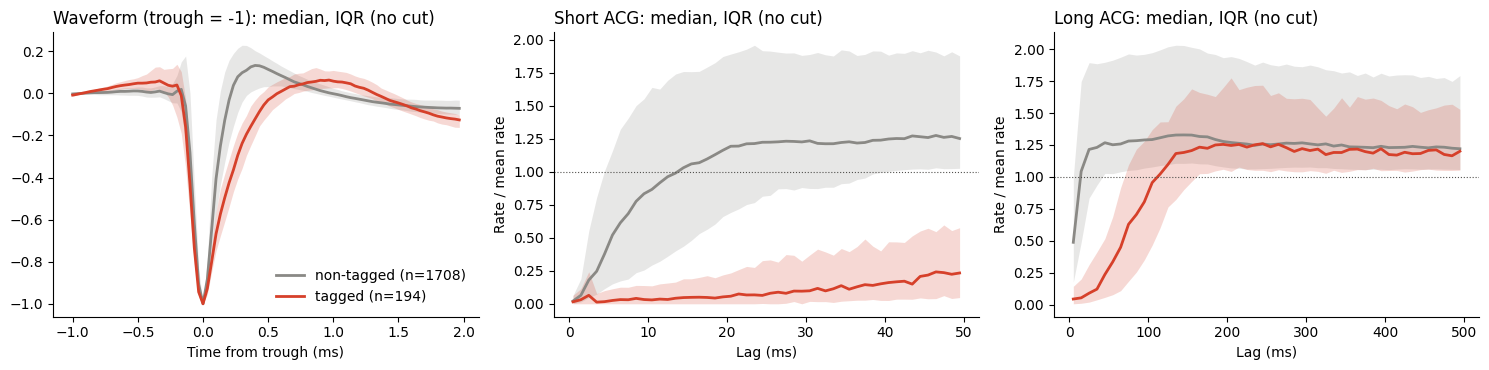

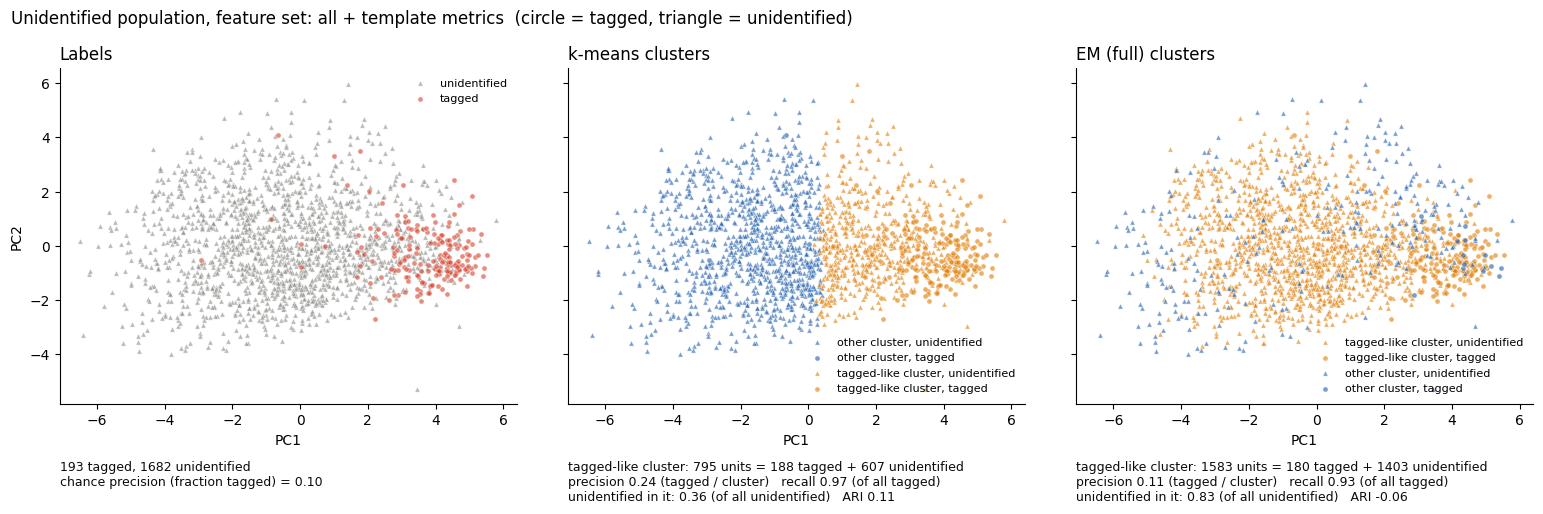

In [16]:
f_u = pops['unidentified: all QC units']
plot_shapes(f_u, ' (no cut)')
plot_clusters(unid_fits[SHOW], f'Unidentified population, feature set: {SHOW}', other_label='unidentified')

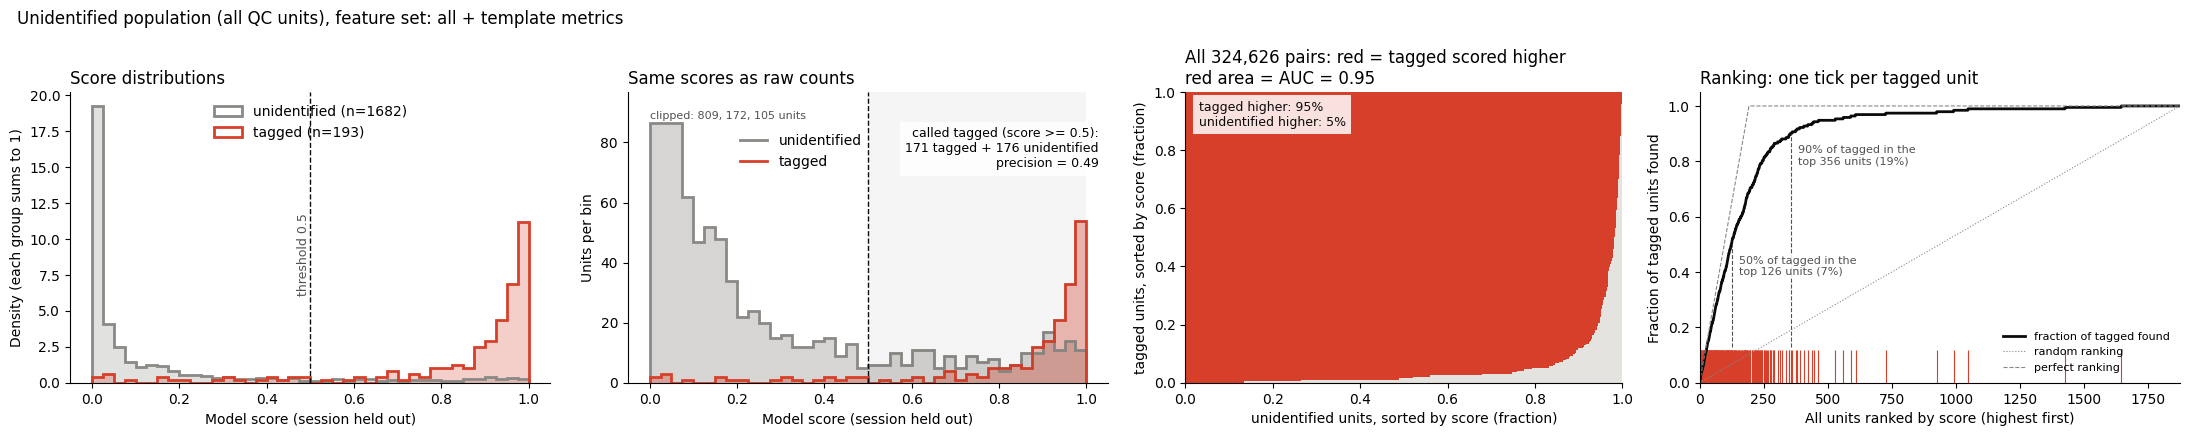

In [17]:
f_u_feat = pops['unidentified: all QC units']['feat']
y_u, p_u = cv_scores(f_u_feat, feature_sets(f_u_feat)[SHOW])
plot_auc_intuition(y_u, p_u, f'Unidentified population (all QC units), feature set: {SHOW}', other_label='unidentified')

#### What the model score and threshold mean
**The score.** The supervised model is a logistic regression. For each unit it takes a weighted sum of the unit's transformed features (left panel below), and squashes that sum to a number between 0 and 1. Features that look like the tagged units push the sum up: wide waveform, deep and long post-spike ACG dip, low LV. Features that look like the rest push it down. So the score is a summary of *how tagged-like this unit looks* on all features at once, and ranking units by it is what the AUC measures.

The weights are standardized coefficients, so their sizes can be compared. Several features are strongly correlated, though (e.g. the ACG dip, half-rise time and LV), so the weight is shared among them in a somewhat arbitrary way. Read the panel as "which kinds of features matter", not as the importance of any single feature.

**What a score is not.** It is not "the probability this unit is tagged". The model was trained with `class_weight='balanced'`, which counts the tagged and non-tagged groups equally, as if half of all units were tagged. A score of 0.5 therefore means "equally likely either way **if tagged units were as common as non-tagged ones**". When only a fraction $\pi$ of units are tagged, the odds have to be scaled down by that rarity:

$$\text{odds(tagged)} \approx \frac{s}{1 - s} \cdot \frac{\pi}{1 - \pi}$$

At $\pi$ = 10%, a score of 0.5 means about a 10% chance of being tagged, a score of 0.9 about 50%, and only scores near 0.98 mean about 85%. The right panel checks this against the data: the observed fraction of tagged units in each score bin of the unidentified population (about 10% tagged), against the curve from the formula.

**The threshold** is simply the cutoff where you decide to *call* a unit tagged. 0.5 is the default, not a special value.
* **Raising it** (e.g. to 0.9) calls fewer units tagged. The ones it calls are more often right (higher precision, higher specificity), but more tagged units are missed (lower sensitivity).
* **Lowering it** does the opposite.

Choose it from what a mistake costs in the analysis that uses the predictions; the threshold table in *Predicting tagged units in new data* lists the trade-off.

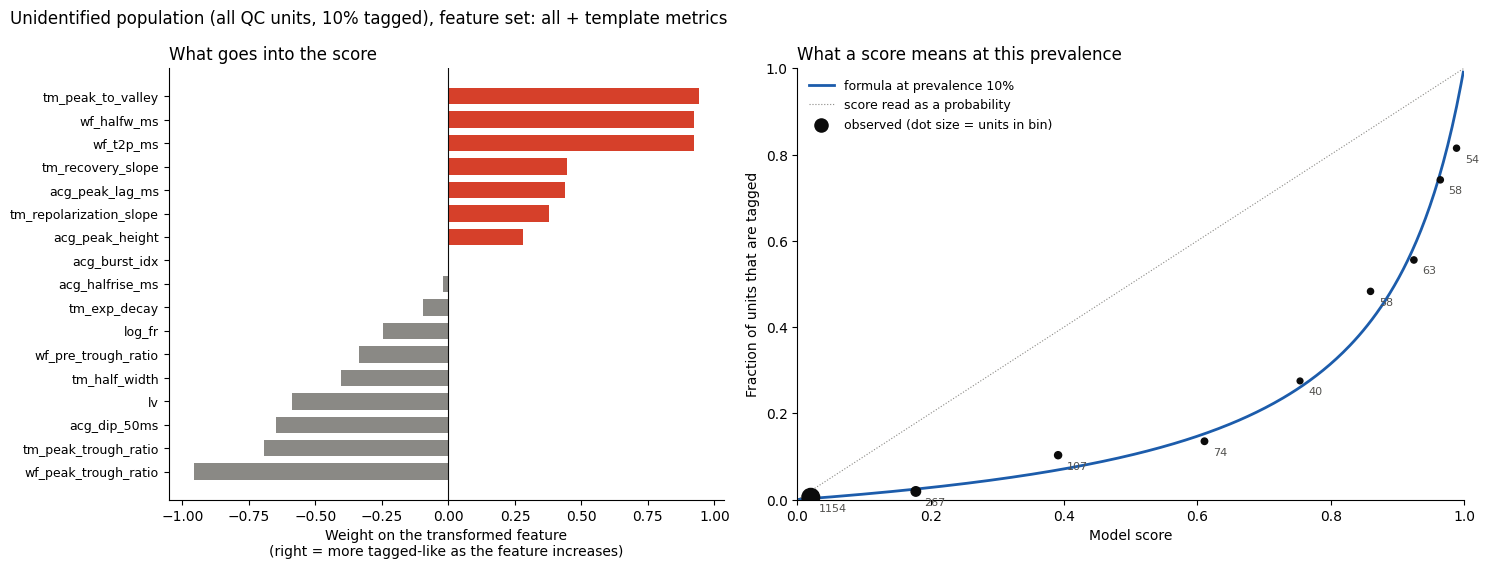

In [18]:
def plot_score_meaning(feat, cols, y, score, prevalence=None, title=''):
    d = feat.dropna(subset=cols)
    clf = make_pipeline(PowerTransformer(), LogisticRegression(max_iter=2000, class_weight='balanced'))
    clf.fit(d[cols].to_numpy(), d['tagged'].to_numpy().astype(int))
    coef = pd.Series(clf[-1].coef_[0], index=cols).sort_values()
    prevalence = np.mean(y) if prevalence is None else prevalence

    fig, axes = plt.subplots(1, 2, figsize=(15, max(4.2, 0.28 * len(cols) + 1)), gridspec_kw={'width_ratios': [1, 1.2]})
    ax = axes[0]
    ax.barh(coef.index, coef.values, color=[TAGGED_COLOR if v > 0 else NONTAGGED_COLOR for v in coef.values], height=0.7)
    ax.axvline(0, color='#0b0b0b', lw=0.8)
    ax.set_xlabel('Weight on the transformed feature\n(right = more tagged-like as the feature increases)')
    ax.set_title('What goes into the score', loc='left')
    ax.tick_params(axis='y', labelsize=9)

    ax = axes[1]
    bins = np.array([0, 0.1, 0.3, 0.5, 0.7, 0.8, 0.9, 0.95, 0.98, 1.0001])
    idx = np.digitize(score, bins) - 1
    obs = pd.DataFrame({'bin': idx, 'y': y, 's': score}).groupby('bin').agg(n=('y', 'size'), frac=('y', 'mean'), s=('s', 'mean'))
    s_grid = np.linspace(0.001, 0.999, 300)
    odds = s_grid / (1 - s_grid) * prevalence / (1 - prevalence)
    ax.plot(s_grid, odds / (1 + odds), color='#1c5cab', lw=2, label=f'formula at prevalence {prevalence:.0%}')
    ax.plot([0, 1], [0, 1], color='#8a8985', lw=0.8, ls=':', label='score read as a probability')
    ax.scatter(obs['s'], obs['frac'], s=12 + obs['n'] / obs['n'].max() * 150, color='#0b0b0b', zorder=3,
               label='observed (dot size = units in bin)')
    for _, r in obs.iterrows():
        ax.annotate(f"{int(r['n'])}", (r['s'], r['frac']), textcoords='offset points', xytext=(6, -10), fontsize=8, color='#52514e')
    ax.set_xlim(0, 1)
    ax.set_ylim(0, 1)
    ax.set_xlabel('Model score')
    ax.set_ylabel('Fraction of units that are tagged')
    ax.set_title('What a score means at this prevalence', loc='left')
    ax.legend(frameon=False, loc='upper left', fontsize=9)
    for ax in axes:
        ax.spines[['top', 'right']].set_visible(False)
    fig.suptitle(title, x=0.01, ha='left')
    fig.tight_layout()


plot_score_meaning(f_u_feat, feature_sets(f_u_feat)[SHOW], y_u, p_u,
                   title=f'Unidentified population (all QC units, {y_u.mean():.0%} tagged), feature set: {SHOW}')

### Within-session check and supervised reference (unidentified population)

In [19]:
cols = ['population', 'features', 'method', 'ARI', 'ARI null 95%', 'p (within-session shuffle)', 'sessions',
        'median session AUC', 'sessions AUC > 0.5']
display(pd.concat(unid_ws)[cols].set_index(['population', 'features', 'method'])
        .style.format({'ARI': '{:.2f}', 'ARI null 95%': '{:.3f}', 'p (within-session shuffle)': '{:.3f}',
                       'median session AUC': '{:.2f}', 'sessions AUC > 0.5': '{:.2f}'}))
display(pd.concat(unid_sup).pivot(index='features', columns='population', values='session-held-out AUC')
        .style.format('{:.2f}'))

population,all QC units,within 0.2 mm of tagged DV range
features,,
ACG,0.92,0.91
ACG + LV,0.92,0.91
ACG PCs,0.92,0.92
ACG PCs + LV,0.92,0.92
LV,0.78,0.76
all,0.96,0.95
all + template metrics,0.95,0.95
firing rate,0.73,0.72
template metrics,0.92,0.91


## Letting BIC choose the number of components (unidentified population)
With G fixed at 2, the large, heterogeneous unidentified group dominates the data, and the split cuts that group in half (see above). Here BIC chooses G from 1 to `G_MAX` together with the covariance type, as `mclust` does when G is not fixed.

Each (G, covariance) fit starts from a Ward partition into G clusters, as in the precedent. It also tries `EM_EXTRA_INITS` k-means++ starts and keeps the best BIC, because single-start fits get stuck in local optima and give a bumpy BIC curve.

Components are then **ranked by the fraction of tagged units** they contain. *Cumulative recall / precision* is what you would get by calling the top 1, 2, ... components "tagged-like".

**Note:** ranking the components uses the labels. With no tagging at all, you would have to name the 5-HT component(s) from their features, e.g. regular firing and a wide waveform, or from a model fit on tagged data.

In [20]:
G_MAX = 10
EM_EXTRA_INITS = 5
BIC_SETS = ['ACG PCs', 'ACG PCs + LV', 'waveform + ACG + LV', 'all', 'all + template metrics']


def em_bic(X):
    """BIC over G = 1..G_MAX and COV_TYPES; Ward-initialized fit plus EM_EXTRA_INITS k-means++
    starts per (G, covariance), keeping the lowest BIC."""
    bic, models = {}, {}
    for G in range(1, G_MAX + 1):
        hc = AgglomerativeClustering(n_clusters=G, linkage='ward').fit_predict(X) if G > 1 else np.zeros(len(X), int)
        means = np.stack([X[hc == k].mean(0) for k in range(G)])
        weights = np.bincount(hc, minlength=G) / len(hc)
        for ct in COV_TYPES:
            fits_ = [GaussianMixture(G, covariance_type=ct, means_init=means, weights_init=weights,
                                     max_iter=1000, reg_covar=1e-4, random_state=SEED).fit(X)]
            if EM_EXTRA_INITS and G > 1:
                fits_.append(GaussianMixture(G, covariance_type=ct, init_params='k-means++', n_init=EM_EXTRA_INITS,
                                             max_iter=1000, reg_covar=1e-4, random_state=SEED).fit(X))
            m = min(fits_, key=lambda m_: m_.bic(X))
            bic[(G, ct)], models[(G, ct)] = m.bic(X), m
    best = min(bic, key=bic.get)
    return best, models[best], bic


def component_table(y, lab, G):
    comp = pd.DataFrame({'units': np.bincount(lab, minlength=G),
                         'tagged': np.bincount(lab, weights=y, minlength=G).astype(int)})
    comp['fraction tagged'] = comp['tagged'] / comp['units'].clip(lower=1)
    comp = comp.sort_values('fraction tagged', ascending=False)
    comp['cum. recall'] = comp['tagged'].cumsum() / y.sum()
    comp['cum. precision'] = comp['tagged'].cumsum() / comp['units'].cumsum()
    return comp


bic_summary, bic_curves, bic_comps = [], {}, {}
for label in unid_versions:
    f_u = pops[f'unidentified: {label}']['feat']
    sets = feature_sets(f_u)
    for name in [n for n in BIC_SETS if n in sets]:
        d = f_u.dropna(subset=sets[name])
        X = transform(d[sets[name]].to_numpy(dtype=float))
        y = d['tagged'].to_numpy()
        (G, ct), m, bic = em_bic(X)
        lab = m.predict(X)
        comp = component_table(y, lab, G)
        bic_comps[(label, name)] = comp
        bic_curves[(label, name)] = pd.Series({G_: min(v for (g_, c), v in bic.items() if g_ == G_) for G_ in range(1, G_MAX + 1)})
        top = comp.iloc[0]
        bic_summary.append({'population': label, 'features': name, 'G': G, 'cov': ct, 'chance precision': y.mean(),
                            'top component units': int(top['units']), 'top recall': top['cum. recall'],
                            'top precision': top['cum. precision'],
                            'top-2 recall': comp['cum. recall'].iloc[min(1, G - 1)],
                            'top-2 precision': comp['cum. precision'].iloc[min(1, G - 1)]})
bic_summary = pd.DataFrame(bic_summary)
display(bic_summary.style.format({c: '{:.2f}' for c in ['chance precision', 'top recall', 'top precision',
                                                         'top-2 recall', 'top-2 precision']}).hide(axis='index'))

population,features,G,cov,chance precision,top component units,top recall,top precision,top-2 recall,top-2 precision
all QC units,ACG PCs,9,full,0.10,210,0.58,0.54,0.72,0.44
all QC units,ACG PCs + LV,10,full,0.10,227,0.63,0.54,0.76,0.47
all QC units,waveform + ACG + LV,6,full,0.10,237,0.74,0.60,0.90,0.31
all QC units,all,10,full,0.10,168,0.52,0.60,0.65,0.44
all QC units,all + template metrics,7,full,0.10,231,0.73,0.61,0.78,0.47
within 0.2 mm of tagged DV range,ACG PCs,10,full,0.22,100,0.39,0.75,0.58,0.72
within 0.2 mm of tagged DV range,ACG PCs + LV,8,full,0.22,139,0.57,0.79,0.70,0.70
within 0.2 mm of tagged DV range,waveform + ACG + LV,4,full,0.22,178,0.73,0.79,0.92,0.48
within 0.2 mm of tagged DV range,all,5,full,0.22,175,0.72,0.79,0.88,0.51
within 0.2 mm of tagged DV range,all + template metrics,5,full,0.22,325,0.85,0.50,0.93,0.45


components for ('all QC units', 'all'), ranked by fraction tagged:


,units,tagged,fraction tagged,cum. recall,cum. precision
4,168,101,0.60,0.52,0.60
2,122,26,0.21,0.65,0.44
0,265,45,0.17,0.89,0.31
5,87,4,0.05,0.91,0.27
6,258,9,0.03,0.95,0.21
1,32,1,0.03,0.96,0.20
7,435,6,0.01,0.99,0.14
3,161,1,0.01,0.99,0.13
9,207,1,0.00,1.00,0.11
8,167,0,0.00,1.00,0.10


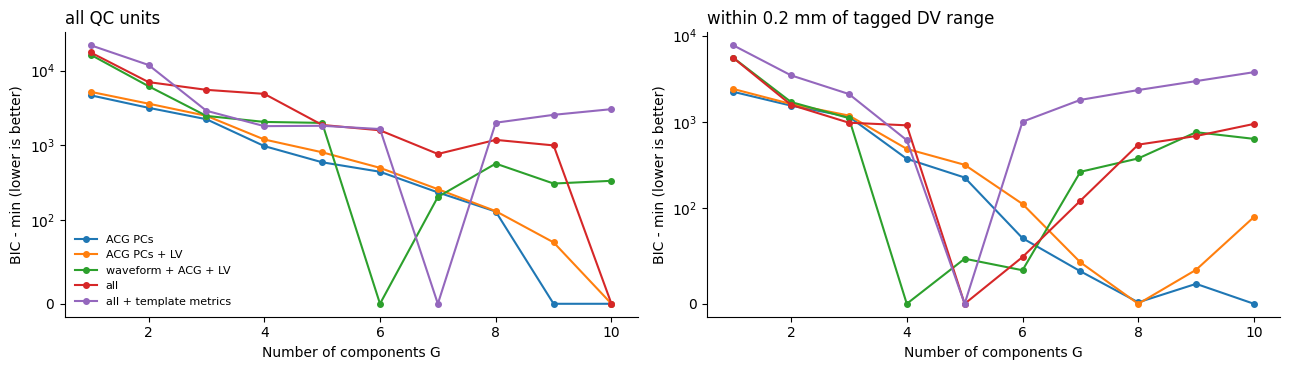

In [21]:
fig, axes = plt.subplots(1, len(unid_versions), figsize=(6.5 * len(unid_versions), 3.8))
for ax, label in zip(np.atleast_1d(axes), unid_versions):
    for name in BIC_SETS:
        if (label, name) in bic_curves:
            c = bic_curves[(label, name)]
            ax.plot(c.index, c - c.min(), marker='o', ms=4, lw=1.5, label=name)
    ax.set_xlabel('Number of components G')
    ax.set_ylabel('BIC - min (lower is better)')
    ax.set_yscale('symlog', linthresh=100)
    ax.set_title(label, loc='left')
    ax.spines[['top', 'right']].set_visible(False)
np.atleast_1d(axes)[0].legend(frameon=False, fontsize=8)
fig.tight_layout()

SHOW_BIC = ('all QC units', 'all')
print(f'components for {SHOW_BIC}, ranked by fraction tagged:')
display(bic_comps[SHOW_BIC].style.format({'fraction tagged': '{:.2f}', 'cum. recall': '{:.2f}', 'cum. precision': '{:.2f}'}))

## Predicting tagged units in new data
This uses the supervised model, since the clusters still need labels to say which one is "tagged". The question is how well it would do on recordings it has never seen, where perhaps ~10% of units are truly tagged.

**Terms**
* **Sensitivity** (recall): of the truly tagged units, the fraction the model calls tagged.
* **Specificity:** of the non-tagged units, the fraction the model correctly calls non-tagged. 1 − specificity is the false-positive rate.
* **Precision** (positive predictive value, PPV): of the units the model *calls* tagged, the fraction that really are.
* **NPV:** of the units it calls non-tagged, the fraction that really are.

Sensitivity and specificity are properties of the model at a given threshold and don't depend on how common tagged units are. PPV and NPV do depend on it:

$$PPV = \frac{sens \cdot p}{sens \cdot p + (1 - spec)(1 - p)}$$

where $p$ is the prevalence. At low prevalence, even a small false-positive rate produces many false positives, because there are so many non-tagged units.

**Setup**
* **Generalization:** whole **mice** are held out (`StratifiedGroupKFold` on mouse), which is closer to "new data" than holding out sessions.
* **Thresholds:** the model's output is a score, not a calibrated probability, because training uses `class_weight='balanced'`. So the threshold is treated as a dial: higher thresholds trade sensitivity for specificity and precision.

held out by session: AUC = 0.955 (42 sessions, 194 tagged / 1902 units)


held out by mouse: AUC = 0.955 (15 mice, 194 tagged / 1902 units)


threshold,sensitivity,specificity,balanced accuracy,PPV @ 5%,PPV @ 10%,PPV @ 20%,NPV @ 10%,per 1000 @ 10%: found / missed / false +
0.5,0.93,0.89,0.91,0.31,0.49,0.69,0.991,93 / 7 / 96
0.7,0.86,0.93,0.90,0.39,0.58,0.75,0.984,86 / 14 / 63
0.8,0.79,0.95,0.87,0.47,0.65,0.81,0.977,79 / 21 / 42
0.9,0.64,0.98,0.81,0.58,0.74,0.87,0.961,64 / 36 / 22


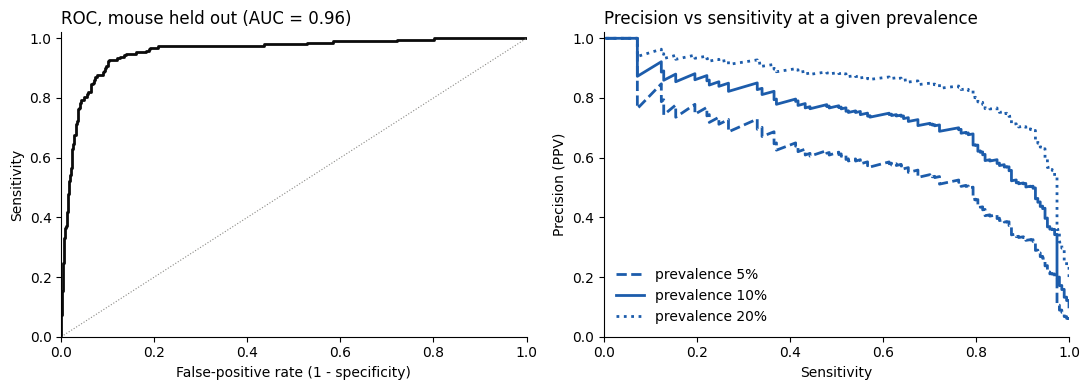

In [22]:
from sklearn.metrics import confusion_matrix, roc_curve

PREVALENCES = [0.05, 0.10, 0.20]
THRESHOLDS = [0.5, 0.7, 0.8, 0.9]
pred_pop = pops['unidentified: all QC units']['feat'].copy()
pred_cols = FEATURE_SETS['all']
d = pred_pop.dropna(subset=pred_cols)
d['mouse'] = d['session'].str.split('_').str[1]
y = d['tagged'].to_numpy().astype(int)
clf = make_pipeline(PowerTransformer(), LogisticRegression(max_iter=2000, class_weight='balanced'))
pred = {}
for grp in ['session', 'mouse']:
    cv = StratifiedGroupKFold(n_splits=5, shuffle=True, random_state=SEED)
    pred[grp] = cross_val_predict(clf, d[pred_cols].to_numpy(), y, cv=cv, groups=d[grp], method='predict_proba')[:, 1]
    print(f'held out by {grp}: AUC = {roc_auc_score(y, pred[grp]):.3f} '
          f"({d[grp].nunique()} {dict(session='sessions', mouse='mice')[grp]}, {y.sum()} tagged / {len(y)} units)")

rows = []
for thr in THRESHOLDS:
    tn, fp, fn, tp = confusion_matrix(y, pred['mouse'] >= thr).ravel()
    se, sp = tp / (tp + fn), tn / (tn + fp)
    row = {'threshold': thr, 'sensitivity': se, 'specificity': sp, 'balanced accuracy': (se + sp) / 2}
    for p in PREVALENCES:
        row[f'PPV @ {p:.0%}'] = se * p / (se * p + (1 - sp) * (1 - p))
    row['NPV @ 10%'] = sp * 0.9 / (sp * 0.9 + (1 - se) * 0.1)
    # per 1000 units at 10% prevalence
    row['per 1000 @ 10%: found / missed / false +'] = f'{100 * se:.0f} / {100 * (1 - se):.0f} / {900 * (1 - sp):.0f}'
    rows.append(row)
pred_tbl = pd.DataFrame(rows)
display(pred_tbl.style.format({c: '{:.2f}' for c in pred_tbl.columns if c not in ['threshold', 'per 1000 @ 10%: found / missed / false +']}
                              | {'threshold': '{:.1f}', 'NPV @ 10%': '{:.3f}'}).hide(axis='index'))

fig, axes = plt.subplots(1, 2, figsize=(11, 4))
fpr, tpr, thr_ = roc_curve(y, pred['mouse'])
axes[0].plot(fpr, tpr, color='#0b0b0b', lw=2)
axes[0].plot([0, 1], [0, 1], color='#8a8985', lw=0.8, ls=':')
axes[0].set_xlabel('False-positive rate (1 - specificity)')
axes[0].set_ylabel('Sensitivity')
axes[0].set_title(f"ROC, mouse held out (AUC = {roc_auc_score(y, pred['mouse']):.2f})", loc='left')
spec_ = 1 - fpr
for p, ls in zip(PREVALENCES, ['--', '-', ':']):
    with np.errstate(invalid='ignore', divide='ignore'):
        ppv = tpr * p / (tpr * p + fpr * (1 - p))
    axes[1].plot(tpr, ppv, color='#1c5cab', lw=2, ls=ls, label=f'prevalence {p:.0%}')
axes[1].set_xlabel('Sensitivity')
axes[1].set_ylabel('Precision (PPV)')
axes[1].set_title('Precision vs sensitivity at a given prevalence', loc='left')
axes[1].legend(frameon=False)
for ax in axes:
    ax.spines[['top', 'right']].set_visible(False)
    ax.set_xlim(0, 1)
    ax.set_ylim(0, 1.02)
fig.tight_layout()

### Fraction confirmed tagged by score decile
Units are sorted by their mouse-held-out model score and split into 10 equal-sized groups (deciles), from the lowest-scoring 10% (decile 1) to the highest-scoring 10% (decile 10). Each bar is the fraction of that decile that is confirmed tagged.
* **Error bars:** 95% intervals from resampling mice.
* **Dashed line:** the population's overall fraction tagged, which is what you'd get by picking units at random.
* **Labels:** above each bar, the count (tagged / units in the decile); below the axis, the decile's score range.

If the score separates the groups well, the bars stay near 0 for low deciles and rise steeply at the top. The populations differ in how common tagged units are, so the same decile reaches a different height in each.

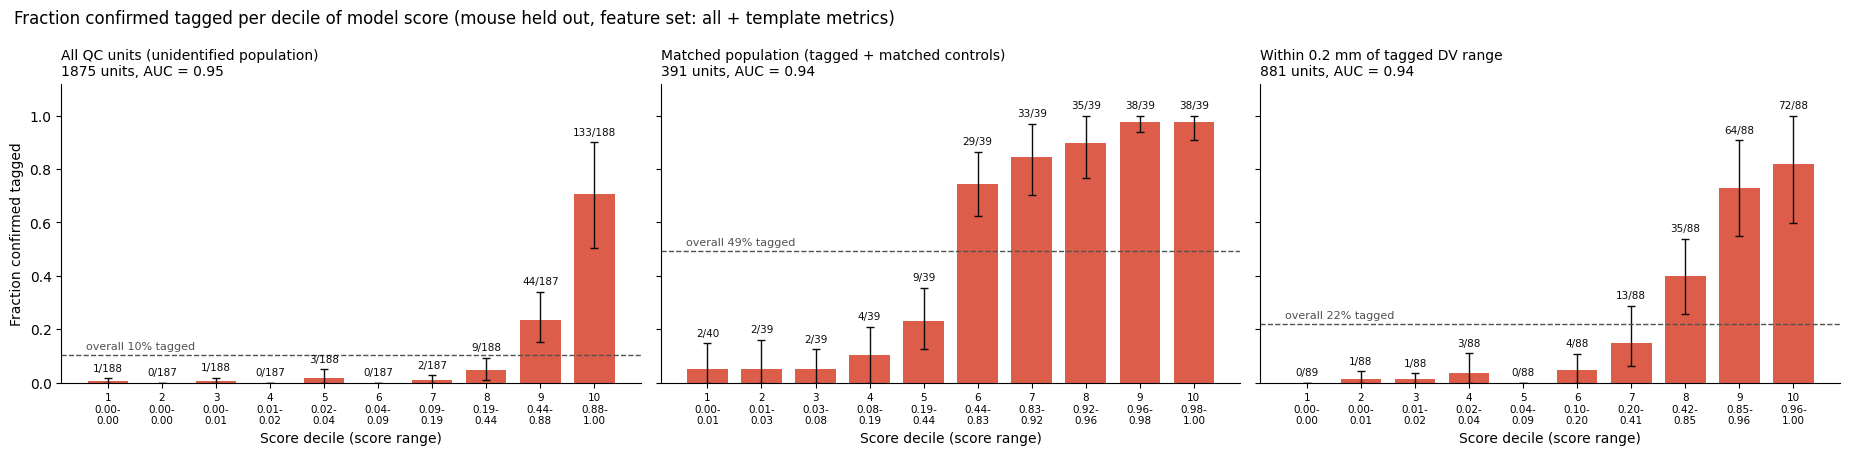

In [23]:
N_BOOT_DECILE = 1000


def mouse_scores(feat, cols):
    d = feat.dropna(subset=cols)
    y = d['tagged'].to_numpy()
    mouse = d['session'].str.split('_').str[1].to_numpy()
    clf = make_pipeline(PowerTransformer(), LogisticRegression(max_iter=2000, class_weight='balanced'))
    cv = StratifiedGroupKFold(n_splits=5, shuffle=True, random_state=SEED)
    p = cross_val_predict(clf, d[cols].to_numpy(), y.astype(int), cv=cv, groups=mouse, method='predict_proba')[:, 1]
    return y, p, mouse


def decile_table(y, p, mouse):
    dec = pd.qcut(pd.Series(p).rank(method='first'), 10, labels=False).to_numpy()
    tbl = pd.DataFrame({'dec': dec, 'y': y, 'p': p}).groupby('dec').agg(
        units=('y', 'size'), tagged=('y', 'sum'), frac=('y', 'mean'), lo=('p', 'min'), hi=('p', 'max'))
    # mice resampled with replacement; deciles kept as assigned on the full data
    boot = np.empty((N_BOOT_DECILE, 10))
    mice = np.unique(mouse)
    idx_by_mouse = {m: np.flatnonzero(mouse == m) for m in mice}
    for b in range(N_BOOT_DECILE):
        idx = np.concatenate([idx_by_mouse[m] for m in RNG.choice(mice, len(mice), replace=True)])
        yb, db = y[idx], dec[idx]
        boot[b] = [yb[db == k].mean() if np.any(db == k) else np.nan for k in range(10)]
    tbl['ci_lo'], tbl['ci_hi'] = np.nanpercentile(boot, 2.5, axis=0), np.nanpercentile(boot, 97.5, axis=0)
    return tbl


decile_pops = {
    'All QC units (unidentified population)': pops['unidentified: all QC units']['feat'],
    'Matched population (tagged + matched controls)': pops['matched']['feat'],
    'Within 0.2 mm of tagged DV range': pops['unidentified: within 0.2 mm of tagged DV range']['feat'],
}
fig, axes = plt.subplots(1, len(decile_pops), figsize=(6.2 * len(decile_pops), 4.6), sharey=True)
decile_tables, decile_scores = {}, {}
for ax, (label, fp) in zip(axes, decile_pops.items()):
    y, p, mouse = mouse_scores(fp, feature_sets(fp)[SHOW])
    decile_scores[label] = (y, p, mouse)
    tbl = decile_table(y, p, mouse)
    decile_tables[label] = tbl
    x = np.arange(1, 11)
    ax.bar(x, tbl['frac'], width=0.75, color=TAGGED_COLOR, alpha=0.85)
    ax.errorbar(x, tbl['frac'], yerr=[tbl['frac'] - tbl['ci_lo'], tbl['ci_hi'] - tbl['frac']],
                fmt='none', ecolor='#0b0b0b', elinewidth=1, capsize=3)
    ax.axhline(y.mean(), color='#52514e', lw=1, ls='--')
    ax.text(0.6, y.mean() + 0.015, f'overall {y.mean():.0%} tagged', fontsize=8, color='#52514e', va='bottom')
    for xi, r in zip(x, tbl.itertuples()):
        ax.text(xi, min(r.ci_hi, 1) + 0.02, f'{int(r.tagged)}/{r.units}', ha='center', va='bottom', fontsize=7.5, color='#0b0b0b')
    ax.set_xticks(x, [f'{k}\n{r.lo:.2f}-\n{r.hi:.2f}' for k, r in zip(x, tbl.itertuples())], fontsize=7.5)
    ax.set_xlabel('Score decile (score range)')
    ax.set_ylim(0, 1.12)
    ax.set_title(f'{label}\n{len(y)} units, AUC = {roc_auc_score(y, p):.2f}', loc='left', fontsize=10)
    ax.spines[['top', 'right']].set_visible(False)
axes[0].set_ylabel('Fraction confirmed tagged')
fig.suptitle(f'Fraction confirmed tagged per decile of model score (mouse held out, feature set: {SHOW})', x=0.01, ha='left')
fig.tight_layout()

### Fraction confirmed tagged by score range
The same scores, binned by **fixed score ranges** (0–0.1, 0.1–0.2, ..., 0.9–1.0) instead of equal-sized groups. Each bar answers "of the units that got a score in this range, what fraction are confirmed tagged?", which is what a cutoff like 0.3 or 0.8 means in practice.
* **Bin sizes are very uneven.** Most units score below 0.1, so the middle ranges hold few units and have wide intervals. The count is printed above each bar, and bins with fewer than 5 units are left empty.
* **Black dots:** the prevalence-adjusted prediction from *What the model score and threshold mean*. That is, the fraction tagged you would expect at the bin's mean score given the population's overall fraction tagged. If the dots sit on the bars, the formula is a good way to turn scores into probabilities in that population.
* **Dotted diagonal:** reading the score directly as a probability. The bars fall below it wherever tagged units are less common than 50%.

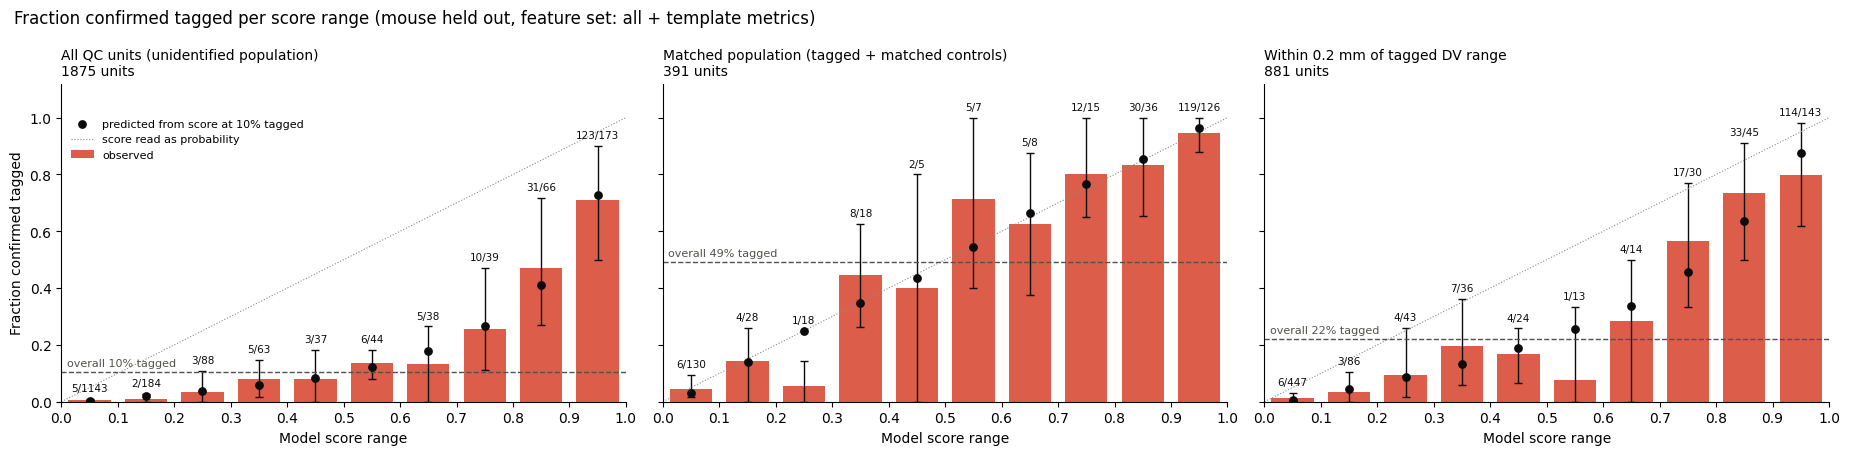

In [24]:
SCORE_EDGES = np.round(np.arange(0, 1.01, 0.1), 2)
MIN_BIN_UNITS = 5


def range_table(y, p, mouse, edges=SCORE_EDGES):
    b = np.clip(np.digitize(p, edges[1:-1]), 0, len(edges) - 2)
    tbl = pd.DataFrame({'b': b, 'y': y, 'p': p}).groupby('b').agg(units=('y', 'size'), tagged=('y', 'sum'),
                                                                  frac=('y', 'mean'), mean_score=('p', 'mean'))
    tbl = tbl.reindex(range(len(edges) - 1))
    tbl['units'] = tbl['units'].fillna(0).astype(int)
    boot = np.full((N_BOOT_DECILE, len(edges) - 1), np.nan)
    mice = np.unique(mouse)
    idx_by_mouse = {m: np.flatnonzero(mouse == m) for m in mice}
    for i in range(N_BOOT_DECILE):
        idx = np.concatenate([idx_by_mouse[m] for m in RNG.choice(mice, len(mice), replace=True)])
        yb, bb = y[idx], b[idx]
        boot[i] = [yb[bb == k].mean() if np.sum(bb == k) >= MIN_BIN_UNITS else np.nan for k in range(len(edges) - 1)]
    with warnings.catch_warnings():
        warnings.simplefilter('ignore', RuntimeWarning)
        tbl['ci_lo'], tbl['ci_hi'] = np.nanpercentile(boot, 2.5, axis=0), np.nanpercentile(boot, 97.5, axis=0)
    prev = y.mean()
    odds = tbl['mean_score'] / (1 - tbl['mean_score']) * prev / (1 - prev)
    tbl['predicted'] = odds / (1 + odds)
    small = tbl['units'] < MIN_BIN_UNITS
    tbl.loc[small, ['frac', 'ci_lo', 'ci_hi', 'predicted']] = np.nan
    return tbl


fig, axes = plt.subplots(1, len(decile_scores), figsize=(6.2 * len(decile_scores), 4.6), sharey=True)
range_tables = {}
centers = (SCORE_EDGES[:-1] + SCORE_EDGES[1:]) / 2
for ax, (label, (y, p, mouse)) in zip(axes, decile_scores.items()):
    tbl = range_table(y, p, mouse)
    range_tables[label] = tbl
    ok = tbl['frac'].notna().to_numpy()
    ax.bar(centers[ok], tbl['frac'][ok], width=0.075, color=TAGGED_COLOR, alpha=0.85, label='observed')
    ax.errorbar(centers[ok], tbl['frac'][ok], yerr=[(tbl['frac'] - tbl['ci_lo'])[ok], (tbl['ci_hi'] - tbl['frac'])[ok]],
                fmt='none', ecolor='#0b0b0b', elinewidth=1, capsize=3)
    ax.scatter(centers[ok], tbl['predicted'][ok], s=28, color='#0b0b0b', zorder=3, label=f'predicted from score at {y.mean():.0%} tagged')
    ax.plot([0, 1], [0, 1], color='#8a8985', lw=0.8, ls=':', label='score read as probability')
    ax.axhline(y.mean(), color='#52514e', lw=1, ls='--')
    ax.text(0.01, y.mean() + 0.015, f'overall {y.mean():.0%} tagged', fontsize=8, color='#52514e', va='bottom')
    for xc, r in zip(centers, tbl.itertuples()):
        top = np.nanmax([r.ci_hi, r.predicted, 0])  # above the error bar and the prediction dot
        txt = f'{int(r.tagged)}/{r.units}' if r.units >= MIN_BIN_UNITS else f'n={r.units}'
        ax.text(xc, min(top, 1) + 0.02, txt, ha='center', va='bottom', fontsize=7.5, color='#0b0b0b' if r.units >= MIN_BIN_UNITS else '#8a8985')
    ax.set_xticks(SCORE_EDGES)
    ax.set_xlim(0, 1)
    ax.set_ylim(0, 1.12)
    ax.set_xlabel('Model score range')
    ax.set_title(f'{label}\n{len(y)} units', loc='left', fontsize=10)
    ax.spines[['top', 'right']].set_visible(False)
axes[0].set_ylabel('Fraction confirmed tagged')
axes[0].legend(frameon=False, fontsize=8, loc='upper left', bbox_to_anchor=(0, 0.92))
fig.suptitle(f'Fraction confirmed tagged per score range (mouse held out, feature set: {SHOW})', x=0.01, ha='left')
fig.tight_layout()

## Next steps
* **Run the precedent exactly** with R `mclust::Mclust(X, G = 2)`, e.g. via rpy2. It covers all 14 covariance models and uses hierarchical initialization (`hc`).
* **Calibrate** the supervised scores to the expected prevalence (e.g. Platt scaling without class weights) so they can be read as probabilities.
* **Automatic drift cuts** for the unidentified population, e.g. the longest window with a stable amplitude and firing rate. The cut vs no-cut comparison above can be used to validate one against the hand-placed cuts.
* **More features:**
  * ISI CV and CV2
  * 2D/spatial waveform spread from `wf_2d`
  * CCF depth